In [2]:

from turtle import delay
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from Models_MLP_tuning import MLP_aif, MLP_myo, MLP_ode
from torch.utils.data import TensorDataset, DataLoader
import torch.nn.functional as F
from tqdm import tqdm
from torch.optim.lr_scheduler import ReduceLROnPlateau, OneCycleLR
from torchmetrics.image import StructuralSimilarityIndexMeasure
from torcheval.metrics import MeanSquaredError as mse_metric
from random import randint, random
from itertools import cycle
from Create_DRO_2 import make_dro_no_delay
import time

%matplotlib inline

In [3]:
import torch

print(torch.__version__)
print(torch.version.cuda)
print(torch.cuda.is_available())

2.5.1
11.8
True


In [4]:
if torch.cuda.is_available():
    device = torch.device("cuda")  # Windows/Linux
    print("gpuuuuuuuuu")

elif torch.backends.mps.is_available():
    device = torch.device("mps")  # MacOS
else:
    device = torch.device("cpu")
    print("cpuuuuu")

gpuuuuuuuuu


In [5]:
def phys_params_to_tt_params_torch(f, vp, ve, ps):

    f, vp, ve, ps = f.to(device), vp.to(device), ve.to(device), ps.to(device)
    tb = vp / f
    tp = vp / (ps + f)
    te = ve / ps

    return tb, tp, te


def tt_params_to_model_params_torch(tb, tp, te):

    tb, tp, te = tb.to(device), tp.to(device), te.to(device)
    k_m = 0.5 * (
        1.0 / tp
        + 1.0 / te
        - torch.sqrt((1.0 / tp + 1.0 / te) ** 2 - 4.0 * (1.0 / tb) * (1.0 / te))
    )
    k_p = 0.5 * ( 1.0 / tp + 1.0 / te + torch.sqrt((1.0 / tp + 1.0 / te) ** 2 - 4.0 * (1.0 / tb) * (1.0 / te))
    )
    d = k_p - k_m
    e = (k_p - 1.0 / tb) / d

    return d, e, k_m

In [6]:
def two_CXM_torch(
    parameters: torch.Tensor, time: torch.Tensor, aif: torch.Tensor, dt: float
) -> torch.Tensor:
    """
    parameters: [N, 4] → Fp, vp, ve, PS
    time: [T] → shared time vector
    aif: [T] or [1,1,T]
    dt: scalar
    returns: [N, T] → modeled tissue curve per voxel
    """
    thres_1 = 1e-4
    thres_2 = 3
    parameters = parameters.to(device)
    N, T = parameters.shape[0], time.shape[-1]
    flow = parameters[..., 0]
    vp = parameters[..., 1]
    ve = parameters[..., 2]
    ps = parameters[..., 3]
    tb, tp, te = phys_params_to_tt_params_torch(flow, vp, ve, ps)
    d, e, km = tt_params_to_model_params_torch(tb, tp, te)

    time = time.clone().detach().to(device).reshape(1, 1, -1)
    aif = aif.clone().detach().to(device).reshape(1, 1, -1)

    exp1 = torch.exp(-km[..., None] * time)  # [1, T]
    exp2 = torch.exp(-(km[..., None] + d[..., None]) * time)  # [1, T]

    aif = torch.flip(aif, dims=[-1])
    # Batched convolution
    conv1 = F.conv1d(exp1, aif, padding=T - 1)
    conv2 = F.conv1d(exp2, aif, padding=T - 1)
    
    conv = flow[:, :, None] * dt * (e[:, :, None] * conv1 + (1 - e[:, :, None]) * conv2)[..., :T]

    return conv

In [8]:
def train_pinn(
    myo_curves, myo_pars, aif_time, aif,
    epochs=3000, lr=1e-4, batch_size=256, seed_value=42,
    num_layers_aif=5, dim_hidden_aif=64, w0_aif=25, w0_initial_aif=15,
    num_layers_myo=5, dim_hidden_myo=128, w0_myo=20, w0_initial_myo=25,
    num_layers_conv=4, dim_hidden_conv=256,w0_conv=10, w0_initial_conv=20,
    loss_w_aif=5.0, loss_w_myo = 10.0, loss_w_conv=10.0,
):

    """
    PINN training function where myocardial concentration is modeled as:

        C_myo = v_e * C_e + v_p * C_p

    model_e predicts C_e
    model_p predicts C_p

    myo_pars[..., 1] = v_p
    myo_pars[..., 2] = v_e
    """

    # myo_curves shape: [T, H, W, 1]
    # myo_pars shape:   [H, W, 1, 4]

    T, H, W, _ = myo_curves.shape
    N = H * W

    print(f"Shape of myo_curves: {myo_curves.shape}")
    print(f"Shape of myo_pars: {myo_pars.shape}")

    # =========================
    # Time and coordinate tensors
    # =========================
    t = torch.tensor(aif_time, dtype=torch.float32).to(device)
    dt = aif_time[1] - aif_time[0]

    x = np.linspace(0, 1, H).astype(np.float32)
    y = np.linspace(0, 1, W).astype(np.float32)

    # Normalized time for MYO model input
    t_norm = np.linspace(0, 2, T).astype(np.float32)

    xx_ode, yy_ode = np.meshgrid(x, y, indexing="ij") # [H,W]
    coords_ode = np.stack([xx_ode, yy_ode], axis=-1).reshape(-1, 2) # [H*W, 2]
    X_tensor_ode = torch.tensor(coords_ode, dtype=torch.float32).to(device) 
    # the same coordinates, will be used for visualization reasons only to distinguish ode from myo

    tt, xx, yy = np.meshgrid(t_norm, x, y, indexing="ij") # [T,H,W]
    coords_txy = np.stack([tt, xx, yy], axis=-1).reshape(-1, 3)  # [T*H*W,3]
    intensities = myo_curves[..., 0].reshape(-1, 1)              # [T*H*W,1]

    X_tensor_myo = torch.tensor(coords_txy, dtype=torch.float32).to(device)
    Y_tensor_myo = torch.tensor(intensities, dtype=torch.float32).to(device)

    # =========================
    # AIF tensors
    # =========================
    t_tensor_aif = torch.tensor(aif_time.reshape(-1, 1),dtype=torch.float32).to(device)
    Y_tensor_aif = torch.tensor(aif.reshape(-1, 1),dtype=torch.float32).to(device)

    #del
    #print(t_tensor_aif)

    # =========================
    # Reshape MYO data by voxel
    # =========================
    X_grouped = X_tensor_myo.view(T, H * W, 3).permute(1, 0, 2)  # [N,T,3]
    Y_grouped = Y_tensor_myo.view(T, H * W, 1).permute(1, 0, 2)  # [N,T,1]

    # =========================
    # Extract vp and ve
    # =========================

    dataset_myo = TensorDataset(
        X_grouped,
        Y_grouped
    )

    loader_myo = DataLoader(
        dataset_myo,
        batch_size=batch_size,
        shuffle=True
    )

    # =========================
    # Models
    # =========================
    torch.manual_seed(seed=seed_value)

    model_aif = MLP_aif(
        num_layers_aif,
        dim_hidden_aif,
        dim_in=1,
        dim_out=1,
        w0_aif=w0_aif,
        w0_initial_aif=w0_initial_aif,
        final_activation=None
    ).to(device)

    model_e = MLP_myo(
        num_layers_myo,
        dim_hidden_myo,
        dim_in=3,
        dim_out=1,
        w0_myo=w0_myo,
        w0_initial_myo=w0_initial_myo,
        final_activation=None
    ).to(device)

    model_p = MLP_myo(
        num_layers_myo,
        dim_hidden_myo,
        dim_in=3,
        dim_out=1,
        w0_myo=w0_myo,
        w0_initial_myo=w0_initial_myo,
        final_activation=None
    ).to(device)

    model_ode = MLP_ode(
          num_layers_conv,
          dim_hidden_conv,
          dim_in=2,
          dim_out=4,
          w0_conv=w0_conv,
          w0_initial_conv=w0_initial_conv,
          final_activation=nn.Softplus()
      ).to(device)

    # =========================
    # Optimizers and loss
    # =========================
    optimizer_aif = optim.Adam(model_aif.parameters(), lr=lr)
    optimizer_e = optim.Adam(model_e.parameters(), lr=lr)
    optimizer_p = optim.Adam(model_p.parameters(), lr=lr)
    optimizer_ode = optim.Adam(model_ode.parameters(), lr)

    # criterion = nn.MSELoss()
    # criterion_pinn = nn.MSELoss() # nn.MSELoss()
    criterion_aif = nn.HuberLoss(delta=10.0) #tuned
    criterion_myo = nn.HuberLoss(delta=0.01) #tuned
    criterion_ode = nn.HuberLoss(delta=0.01) #tuned
    

    ssim_metric = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)

    #following two lines copied for ode implant
    myo_eval = torch.tensor(myo_curves, dtype=torch.float32).squeeze(-1).to(device)
    ssim_metric_par = StructuralSimilarityIndexMeasure(data_range=None).to(device)

    total_losses = []
    cost_array = np.zeros((epochs, 4))

    # =========================
    # Training loop
    # =========================
    
    for epoch in tqdm(range(epochs)):

        if epoch==200:
            new_lr = 1e-5
            optimizer_aif = optim.Adam(model_aif.parameters(), lr=new_lr)
            optimizer_e = optim.Adam(model_e.parameters(), lr=new_lr)
            optimizer_p = optim.Adam(model_p.parameters(), lr=new_lr)
            optimizer_ode = optim.Adam(model_ode.parameters(), lr=new_lr)

        if epoch==1000:
            new_lr = 3e-6
            optimizer_aif = optim.Adam(model_aif.parameters(), lr=new_lr)
            optimizer_e = optim.Adam(model_e.parameters(), lr=new_lr)
            optimizer_p = optim.Adam(model_p.parameters(), lr=new_lr)
            optimizer_ode = optim.Adam(model_ode.parameters(), lr=new_lr)

        model_aif.train()
        model_e.train()
        model_p.train()
        model_ode.train()

        total_epoch_loss = 0.0

        i = 0
        for X_myo_batch, Y_myo_batch in loader_myo:

            optimizer_aif.zero_grad()
            optimizer_e.zero_grad()
            optimizer_p.zero_grad()
            optimizer_ode.zero_grad()

            X_myo_batch = X_myo_batch.to(device)
            Y_myo_batch = Y_myo_batch.to(device)
            #voxel_id_batch = voxel_id_batch.squeeze(-1).to(device)

            B, T_batch, _ = X_myo_batch.shape

            #t_input = X_myo_batch[..., :1].reshape(-1, 1)   # [B*T,1]
            t_input = X_myo_batch[..., :1].reshape(-1, 1).clone().detach().requires_grad_(True)   # [B*T,1]
            xy_input = X_myo_batch[..., 1:].reshape(-1, 2)  # [B*T,2]

            Y_target = Y_myo_batch.view(B, T_batch)         # [B,T]

            # =========================
            # AIF prediction and loss
            # =========================
            pred_aif = model_aif(t_tensor_aif)              # [T,1]
            loss_aif = criterion_aif(pred_aif, Y_tensor_aif)

            # =========================
            # Predict C_e and C_p
            # =========================
            pred_e = model_e(t_input, xy_input)             # [B*T,1]
            pred_p = model_p(t_input, xy_input)             # [B*T,1]

            C_e = pred_e.view(B, T_batch)                   # [B,T]
            C_p = pred_p.view(B, T_batch)                   # [B,T]

            xy_coords = X_myo_batch[:, 0, 1:].to(device)
            #params_pred = model_ode(xy_coords)                         # [B, 4]
            params_pred = model_ode(xy_coords)  

            Fp = params_pred[:, 0:1]            # [B,1]
            vp = params_pred[:, 1:2]            # [B,1]
            ve = params_pred[:, 2:3]            # [B,1]
            PS = params_pred[:, 3:4]            # [B,1]


            # =========================
            # C_myo = ve * Ce + vp * Cp
            # =========================
            C_myo_from_e = ve * C_e                         # [B,T]
            C_myo_from_p = vp * C_p                         # [B,T]
            C_myo_pred = C_myo_from_e + C_myo_from_p        # [B,T]

            loss_myo = criterion_myo(C_myo_pred, Y_target)

            ########### loss_convolution
            params = params_pred.unsqueeze(1)
            convolved = two_CXM_torch(params, t, pred_aif, dt)           # [B, 1, T]
            loss_convolution = criterion_ode(C_myo_pred.unsqueeze(1), convolved)

            total_loss = loss_w_aif * loss_aif + loss_w_myo * loss_myo + loss_w_conv * loss_convolution
            

            # =========================
            # Backprop
            # =========================
            total_loss.backward()

            optimizer_aif.step()
            optimizer_e.step()
            optimizer_p.step()
            optimizer_ode.step()

            total_epoch_loss += total_loss.item()

            if i==0 and 0==1:
                print(t_input)
                print(t)
                print(t_norm)
                i+=1
        
        model_aif.eval()
        model_ode.eval()
        ssim_metric_par = StructuralSimilarityIndexMeasure(data_range=None).to(device)
        with torch.no_grad():
            # Predict parameters from the full tensor
            # pred_aif = model_aif(t_tensor_aif)
            params_pred = model_ode(X_tensor_ode) # shape: [N, 4]
            params = params_pred.reshape(-1, 1, 4)  # shape: [N,1,4]

            # # Reshape parameters for saving and visualization
            params_reshape = params.view(H, W, 1, 4) # shape: [H,W,1,4]

            # # Save values to .txt files
            params_np = params_reshape.cpu().numpy()

            Fp_vals = params_np[..., 0, 0]  # shape: [H,W]
            vp_vals = params_np[..., 0, 1] # shape: [H,W]
            ve_vals = params_np[..., 0, 2] # shape: [H,W]
            ps_vals = params_np[..., 0, 3] # shape: [H,W]

            #print(myo_pars.shape)
            # Generate parameter heatmaps
            cost_Fp = np.sum( ( Fp_vals - myo_pars[..., 0, 0] )**2 )
            cost_vp = np.sum( ( vp_vals - myo_pars[:,:, 0, 1] )**2 )
            cost_ve = np.sum( ( ve_vals - myo_pars[..., 0, 2] )**2 )
            cost_ps = np.sum( ( ps_vals - myo_pars[..., 0, 3] )**2 )
            cost_array[epoch] = np.array([cost_Fp, cost_vp, cost_ve, cost_ps])

            # cost_Fp = np.mean( ( Fp_vals - myo_pars[..., 0, 0] )**2 )
            # cost_vp = np.mean( ( vp_vals - myo_pars[:,:, 0, 1] )**2 )
            # cost_ve = np.mean( ( ve_vals - myo_pars[..., 0, 2] )**2 )
            # cost_ps = np.mean( ( ps_vals - myo_pars[..., 0, 3] )**2 )
            # cost_array_norm[epoch] = np.array([cost_Fp, cost_vp, cost_ve, cost_ps])

        total_losses.append(total_epoch_loss)

    model_aif.eval()
    model_ode.eval()
    ssim_metric_par = StructuralSimilarityIndexMeasure(data_range=None).to(device)
    with torch.no_grad():
        # Predict parameters from the full tensor
        # pred_aif = model_aif(t_tensor_aif)
        params_pred = model_ode(X_tensor_ode) # shape: [N, 4]
        params = params_pred.reshape(-1, 1, 4)

        # # Reshape parameters for saving and visualization
        params_reshape = params.view(H, W, 1, 4)

        # # Save values to .txt files
        params_np = params_reshape.cpu().numpy()
        # print("Params tensor shape:", params.shape)
        # print(params)
        # print("Params shape after reshape:", params_np.shape)
        # print(params_np)
        Fp_vals = params_np[..., 0, 0]
        vp_vals = params_np[..., 0, 1]
        ve_vals = params_np[..., 0, 2]
        ps_vals = params_np[..., 0, 3]

        # Generate parameter heatmaps
        Fp_map = Fp_vals
        vp_map = vp_vals
        ve_map = ve_vals
        ps_map = ps_vals

        # visualise predicted parameters
        fig, axs = plt.subplots(1, 4, figsize=(20, 4))
        im_0 = axs[0].imshow(Fp_map.T, vmin=np.min(Fp_map), vmax=np.max(Fp_map), cmap="plasma")
        axs[0].set_title("Fp Heatmap")
        im_1 = axs[1].imshow(vp_map.T, vmin=np.min(vp_map), vmax=0.20, cmap="plasma")
        axs[1].set_title("vp Heatmap")
        im_2 = axs[2].imshow(ve_map.T, vmin=0.01, vmax=0.5, cmap="plasma")
        axs[2].set_title("ve Heatmap")
        im_3 = axs[3].imshow(ps_map.T, vmin=0.0, vmax=3.5, cmap="plasma")
        axs[3].set_title("PS Heatmap")
        plt.tight_layout()
        # plt.show()
        #plt.close()

        for ax in axs:
            ax.axis("off")
        cbar_0 = fig.colorbar(im_0, ax=axs[0], fraction=0.046, pad=0.04)
        #cbar0.set_label("")
        cbar_1 = fig.colorbar(im_1, ax=axs[1], fraction=0.046, pad=0.04)
        #cbar1.set_label("")
        cbar_2 = fig.colorbar(im_2, ax=axs[2], fraction=0.046, pad=0.04)
        #cbar2.set_label("")
        cbar_3 = fig.colorbar(im_3, ax=axs[3], fraction=0.046, pad=0.04)
        #cbar3.set_label("")
        plt.tight_layout()
        plt.savefig("parameter_heatmaps_orig_enhanced_red.png")
        plt.show()
        plt.close()

        Fp_GT = myo_pars[..., 0, 0]
        vp_GT = myo_pars[..., 0, 1]
        ve_GT = myo_pars[..., 0, 2]
        ps_GT = myo_pars[..., 0, 3]

        # visualise abs difference of predicted parameters versus GT
        fig, axs = plt.subplots(1, 4, figsize=(20, 4))
        im_0 = axs[0].imshow(Fp_GT.T, vmin=np.min(Fp_GT), vmax=np.max(Fp_GT), cmap="plasma")
        axs[0].set_title("Fp Heatmap GT")
        im_1 = axs[1].imshow(vp_GT.T, vmin=np.min(vp_GT), vmax=np.max(vp_GT), cmap="plasma")
        axs[1].set_title("vp Heatmap GT")
        im_2 = axs[2].imshow(ve_GT.T, vmin=np.min(ve_GT), vmax=np.max(ve_GT), cmap="plasma")
        axs[2].set_title("ve Heatmap GT")
        im_3 = axs[3].imshow(ps_GT.T, vmin=np.min(ps_GT), vmax=np.max(ps_GT), cmap="plasma")
        axs[3].set_title("PS Heatmap GT")
        plt.tight_layout()
        # plt.show()
        #plt.close()

        for ax in axs:
            ax.axis("off")
        cbar_0 = fig.colorbar(im_0, ax=axs[0], fraction=0.046, pad=0.04)
        #cbar0.set_label("")
        cbar_1 = fig.colorbar(im_1, ax=axs[1], fraction=0.046, pad=0.04)
        #cbar1.set_label("")
        cbar_2 = fig.colorbar(im_2, ax=axs[2], fraction=0.046, pad=0.04)
        #cbar2.set_label("")
        cbar_3 = fig.colorbar(im_3, ax=axs[3], fraction=0.046, pad=0.04)
        #cbar3.set_label("")
        plt.tight_layout()
        plt.savefig("parameter_heatmaps_cgtp_implant_GT.png")
        plt.show()
        plt.close()

        d_Fp = np.abs(Fp_map - Fp_GT)
        d_vp = np.abs(vp_map - vp_GT)
        d_ve = np.abs(ve_map - ve_GT)
        d_ps = np.abs(ps_map - ps_GT)

        # visualise abs difference of predicted parameters versus GT
        fig, axs = plt.subplots(1, 4, figsize=(20, 4))
        im_0 = axs[0].imshow(d_Fp.T, vmin=np.min(d_Fp), vmax=np.max(d_Fp), cmap="plasma")
        axs[0].set_title("|Fp predicted - Fp GT|")
        im_1 = axs[1].imshow(d_vp.T, vmin=np.min(d_vp), vmax=0.20, cmap="plasma")
        axs[1].set_title("|vp predicted - vp GT|")
        im_2 = axs[2].imshow(d_ve.T, vmin=0.01, vmax=0.5, cmap="plasma")
        axs[2].set_title("|ve predicted - ve GT|")
        im_3 = axs[3].imshow(d_ps.T, vmin=1.5, vmax=3.5, cmap="plasma")
        axs[3].set_title("|PS predicted - PS GT|")
        plt.tight_layout()
        # plt.show()
        #plt.close()

        for ax in axs:
            ax.axis("off")
        cbar_0 = fig.colorbar(im_0, ax=axs[0], fraction=0.046, pad=0.04)
        #cbar0.set_label("")
        cbar_1 = fig.colorbar(im_1, ax=axs[1], fraction=0.046, pad=0.04)
        #cbar1.set_label("")
        cbar_2 = fig.colorbar(im_2, ax=axs[2], fraction=0.046, pad=0.04)
        #cbar2.set_label("")
        cbar_3 = fig.colorbar(im_3, ax=axs[3], fraction=0.046, pad=0.04)
        #cbar3.set_label("")
        plt.tight_layout()
        plt.savefig("parameter_heatmaps_orig_enhanced_red.png")
        plt.show()
        plt.close()

    cost_list = cost_array
    
    return model_aif, model_e, model_p, model_ode, total_losses, cost_list

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)


100%|██████████| 300/300 [01:15<00:00,  3.99it/s]


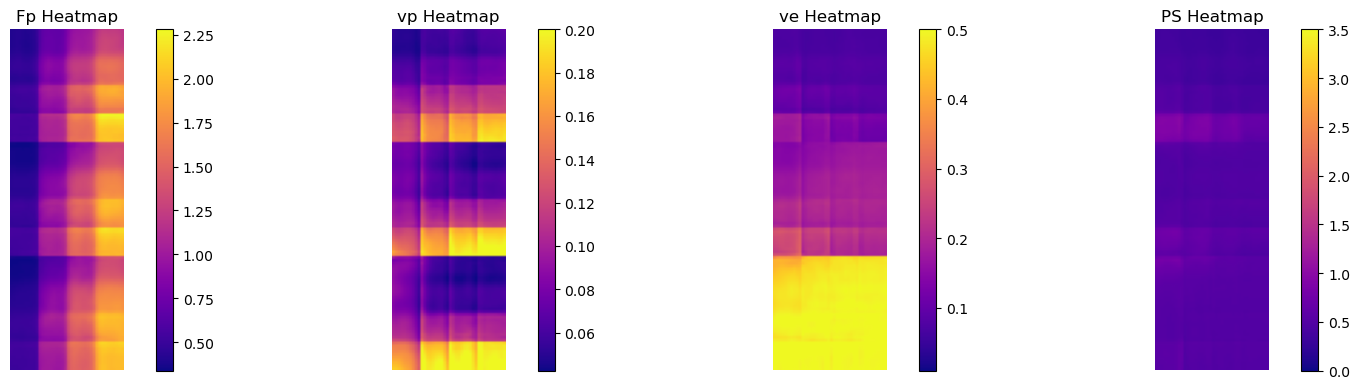

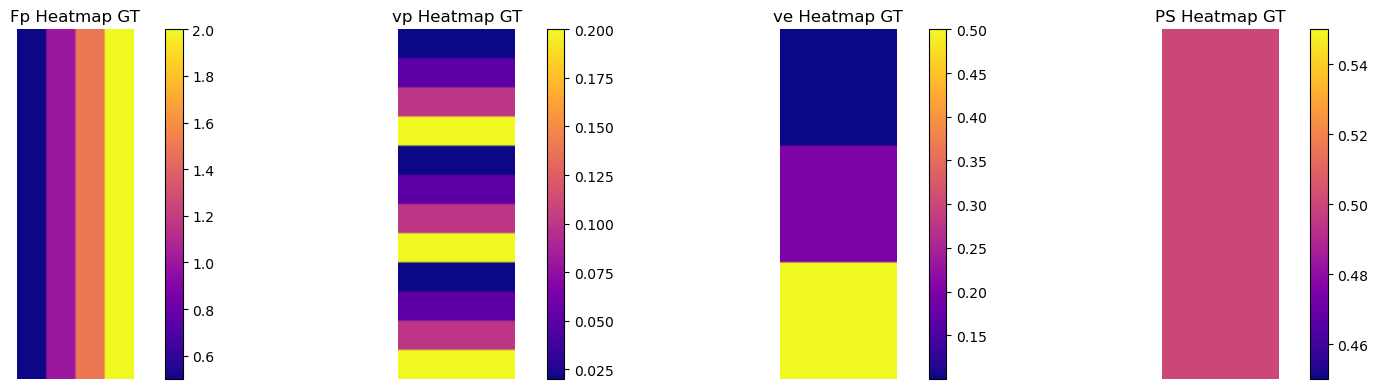

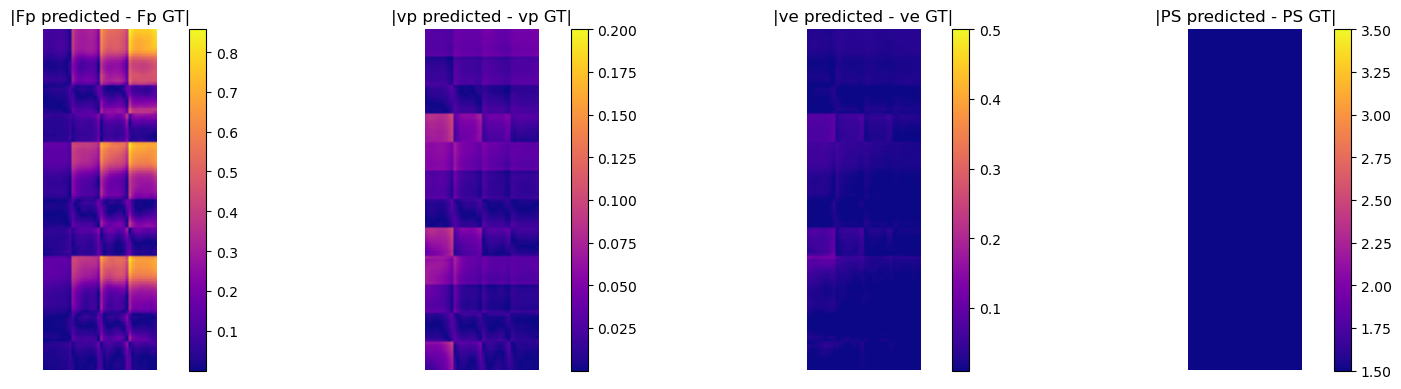

396.0690836906433


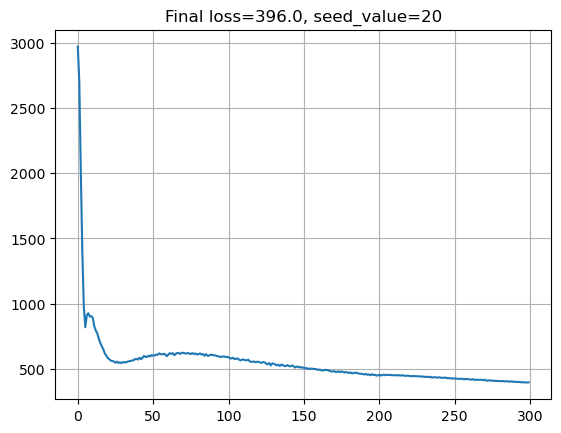

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)


100%|██████████| 300/300 [01:15<00:00,  4.00it/s]


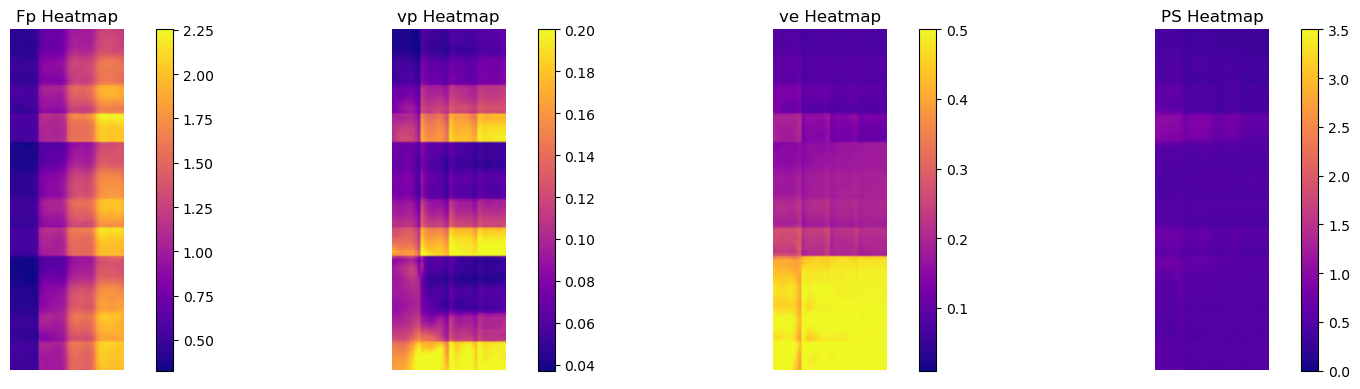

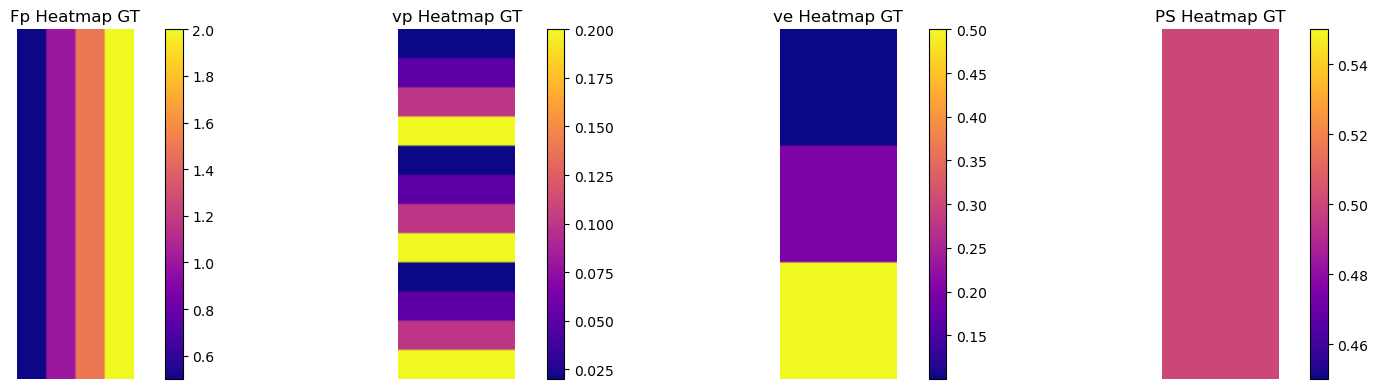

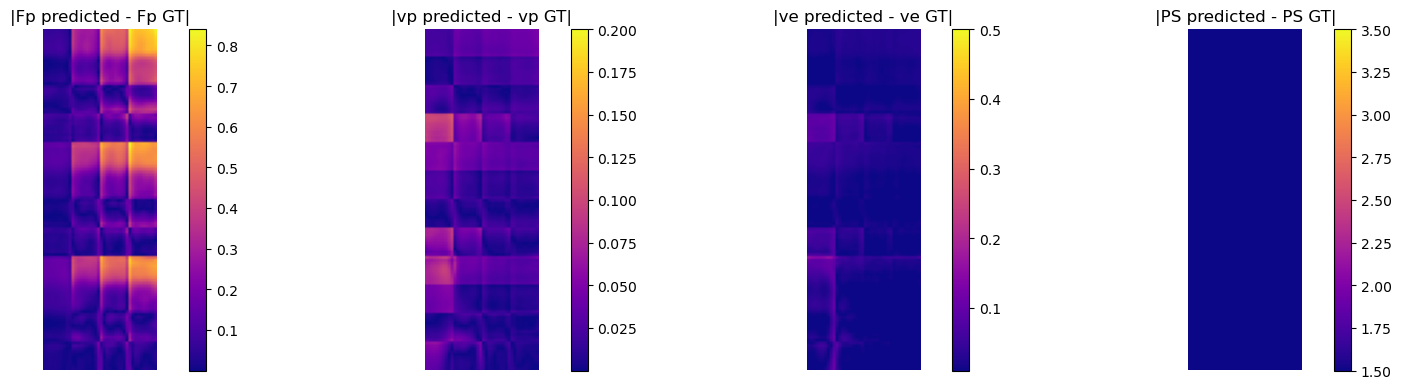

374.7257490158081


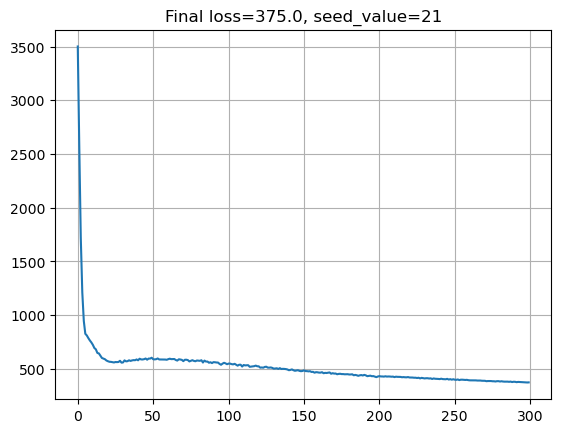

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)


100%|██████████| 300/300 [01:14<00:00,  4.01it/s]


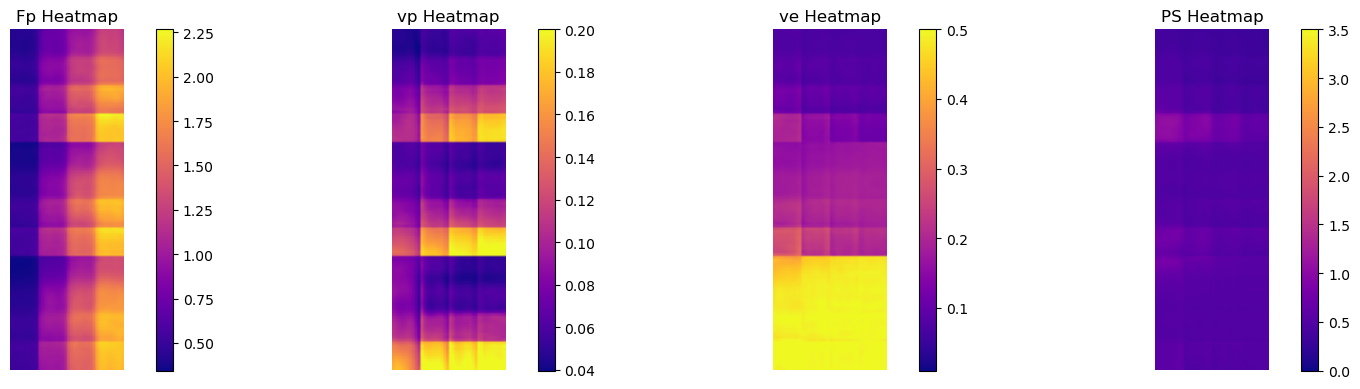

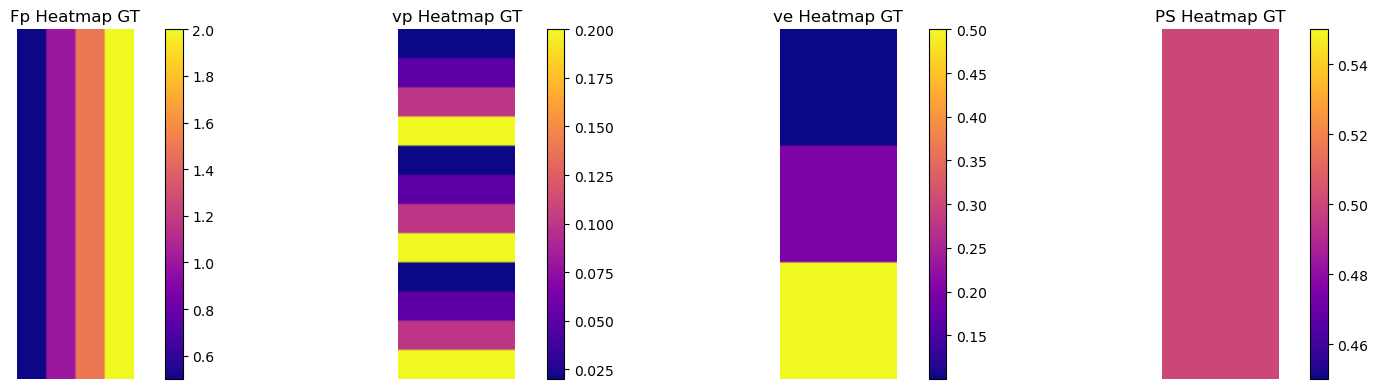

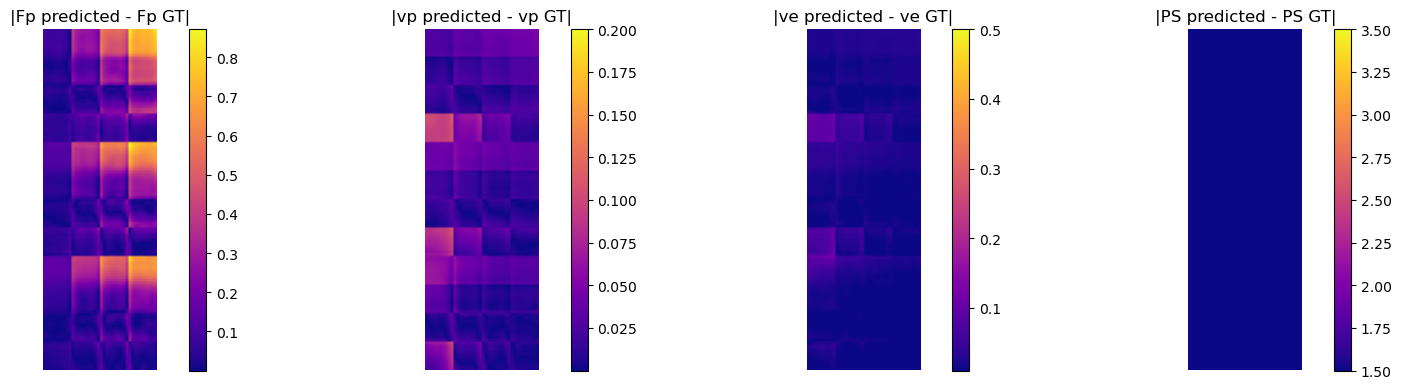

407.11694526672363


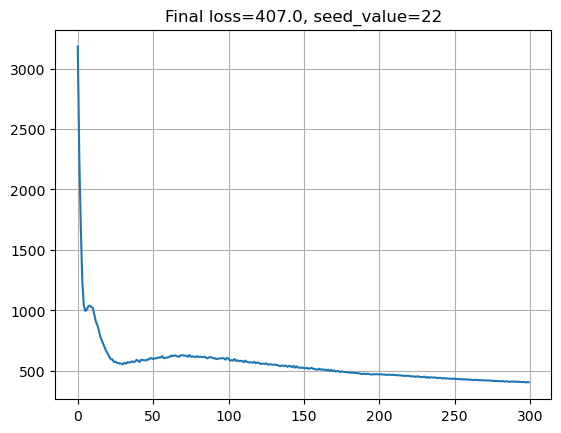

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)


100%|██████████| 300/300 [01:14<00:00,  4.02it/s]


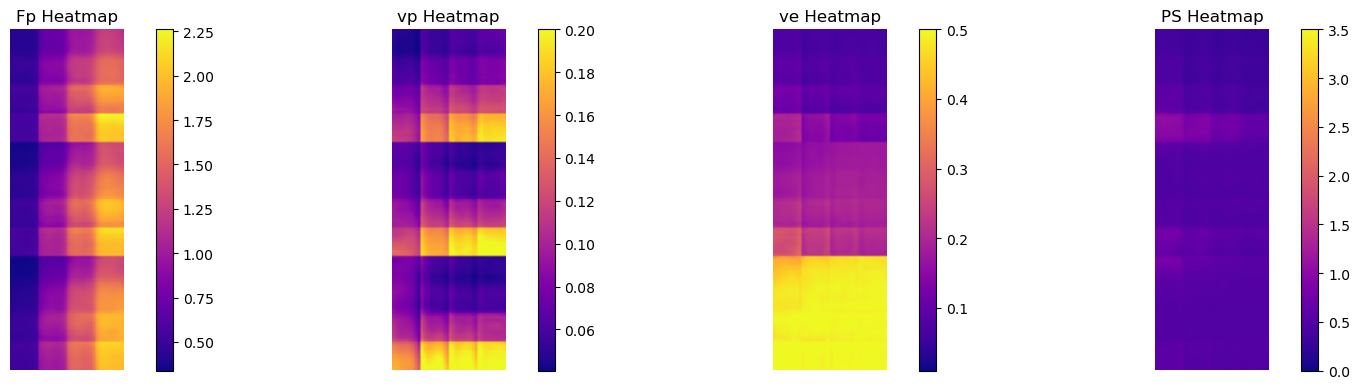

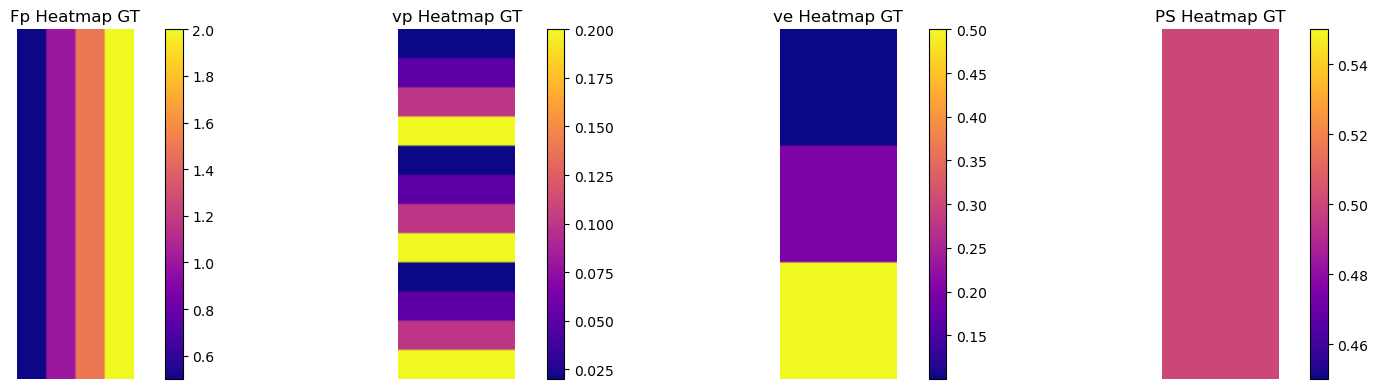

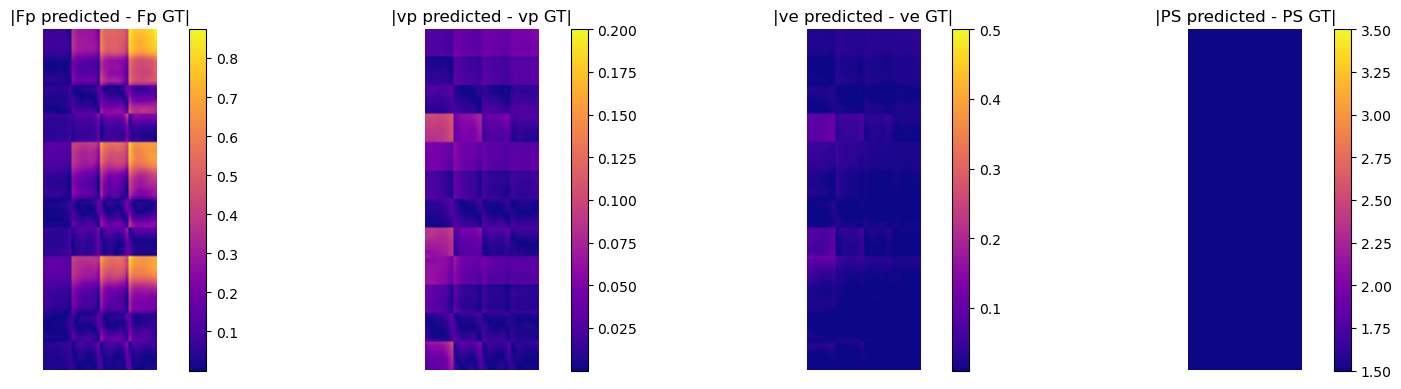

413.9291949272156


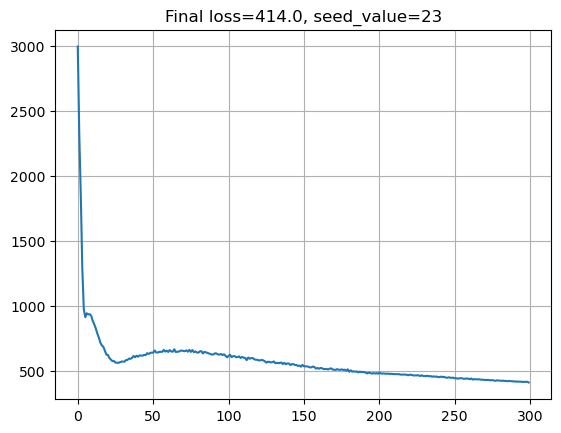

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)


100%|██████████| 300/300 [01:15<00:00,  4.00it/s]


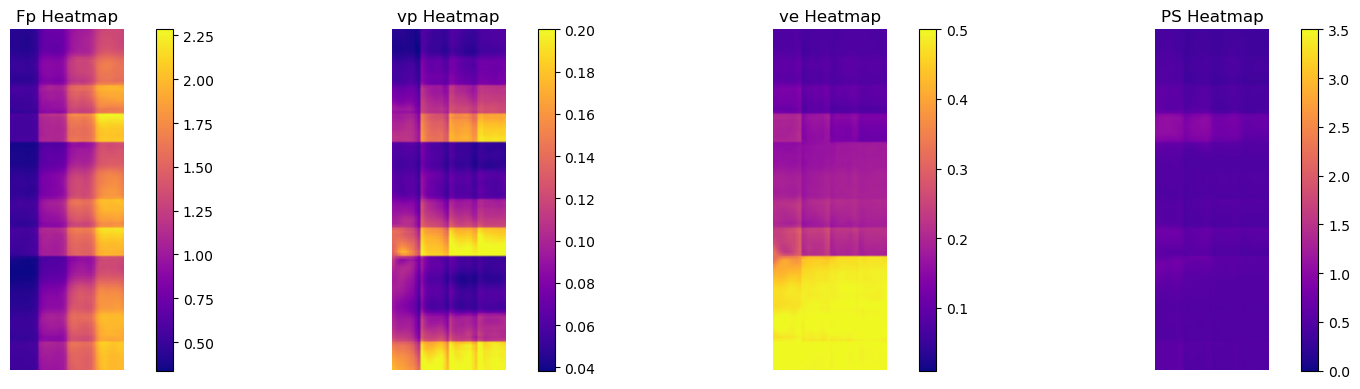

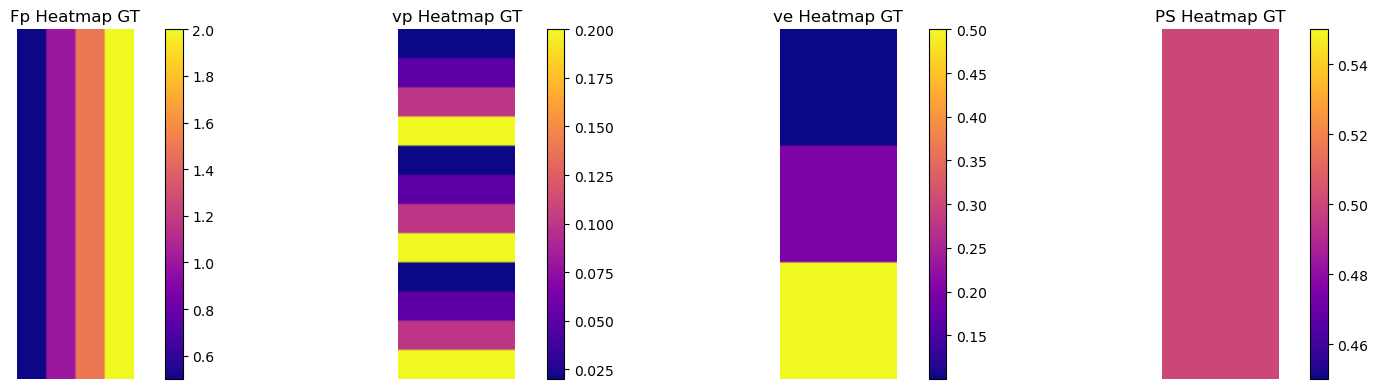

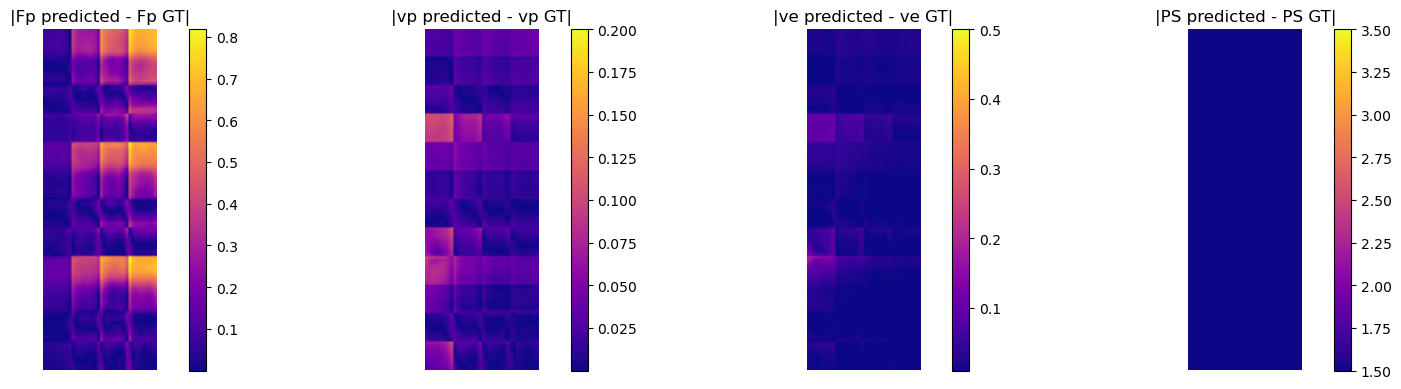

383.8289575576782


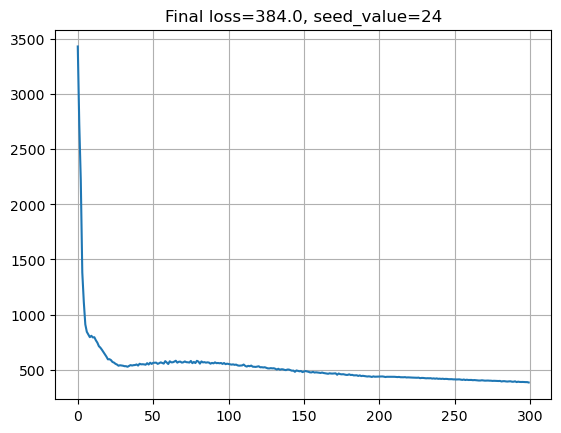

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)


100%|██████████| 300/300 [01:14<00:00,  4.01it/s]


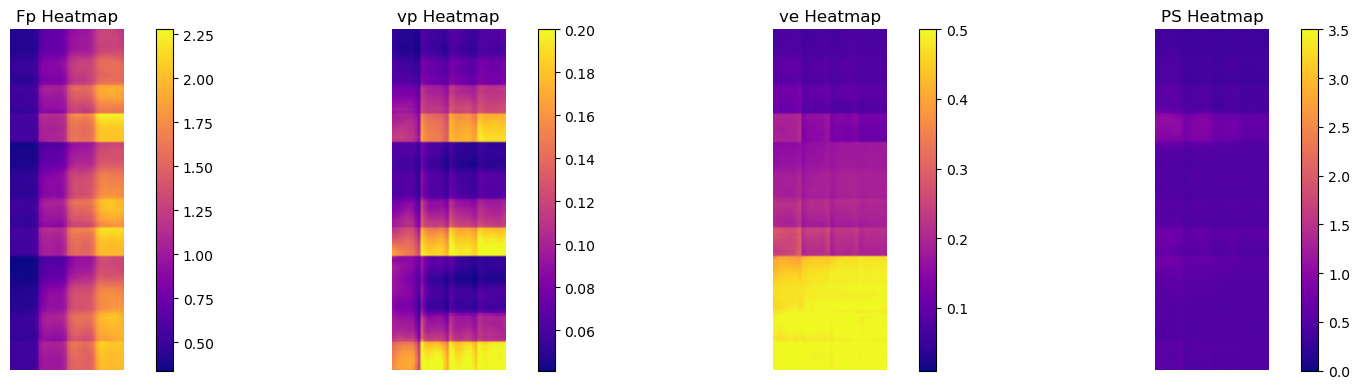

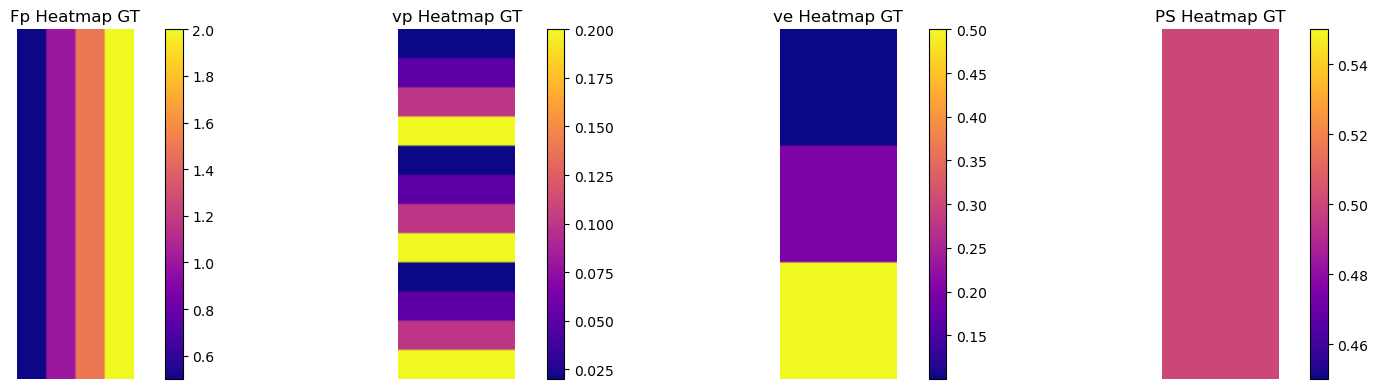

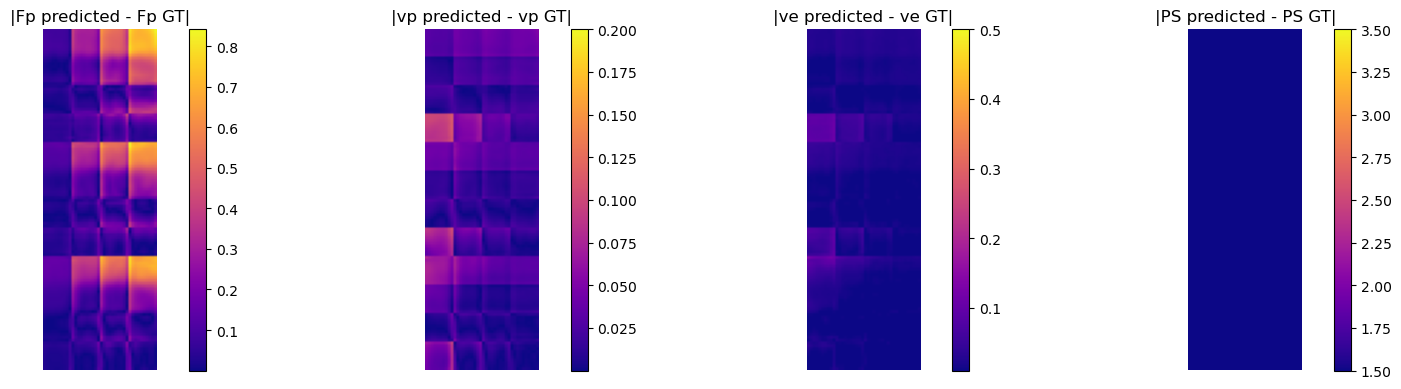

398.6821346282959


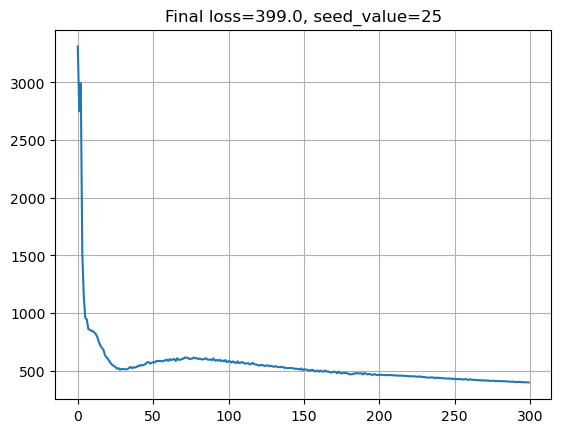

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)


100%|██████████| 300/300 [01:14<00:00,  4.02it/s]


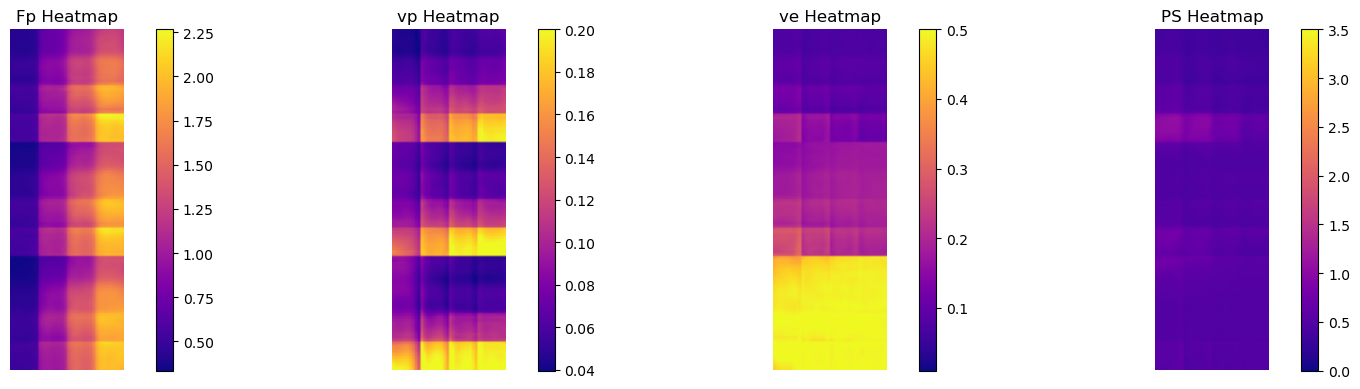

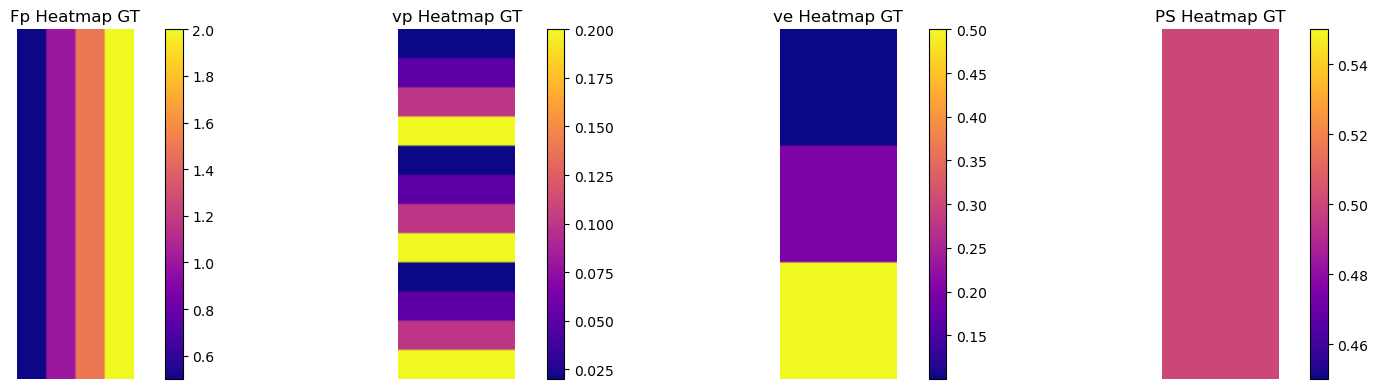

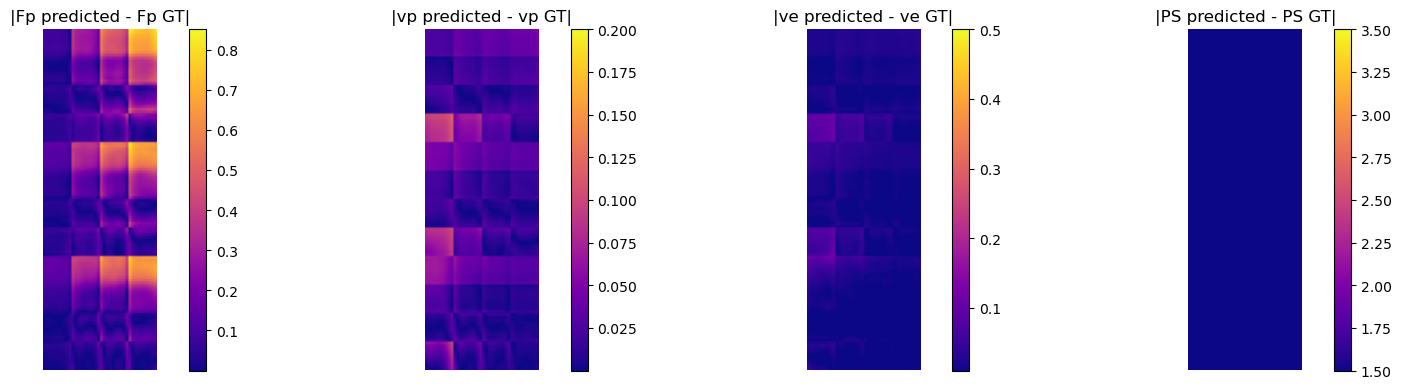

384.78086948394775


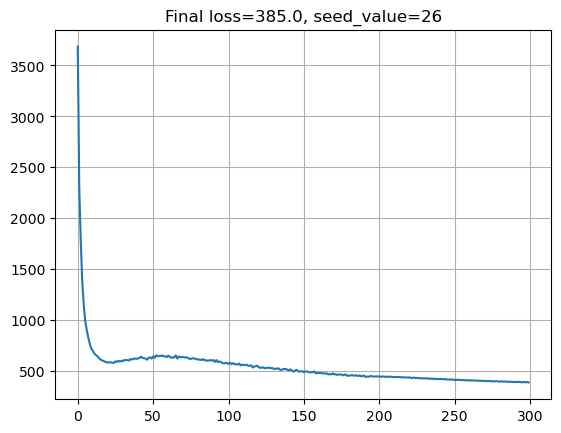

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)


100%|██████████| 300/300 [01:14<00:00,  4.00it/s]


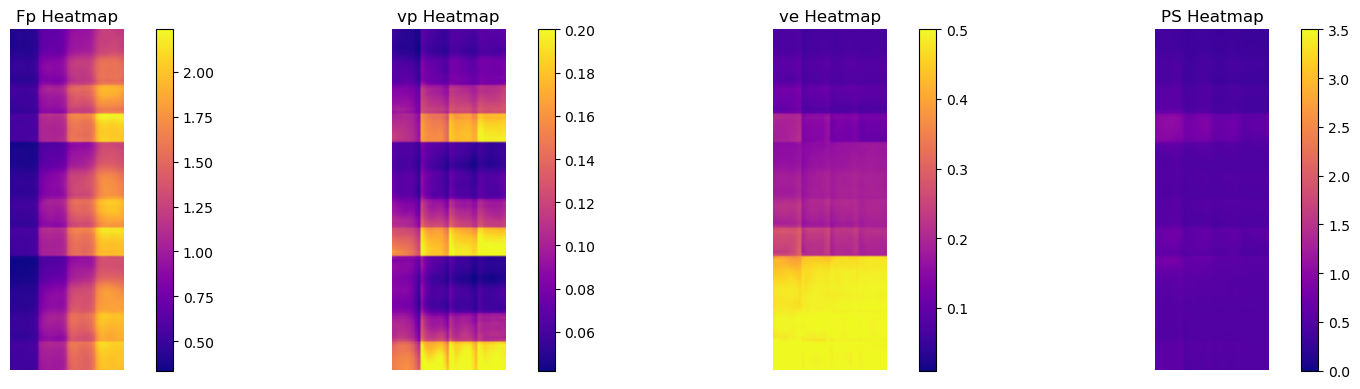

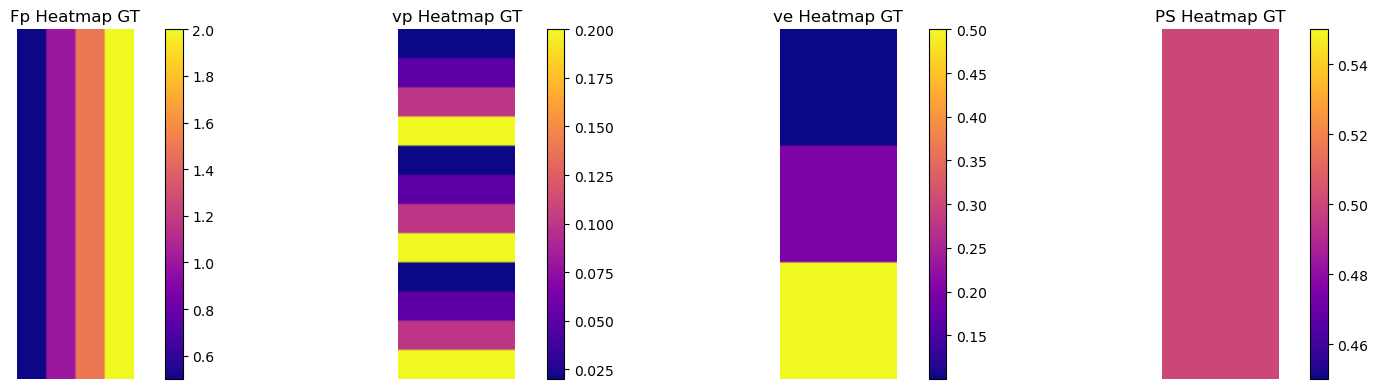

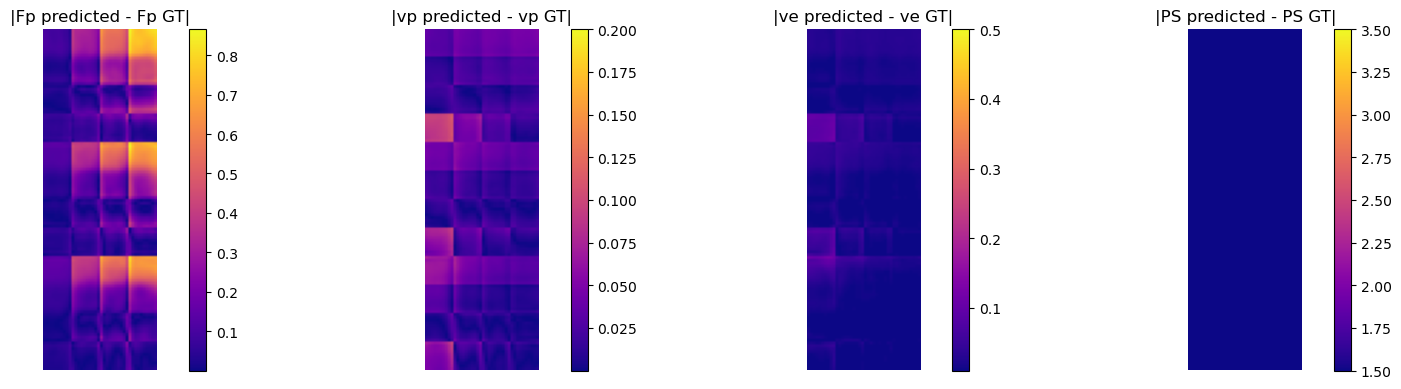

413.6139087677002


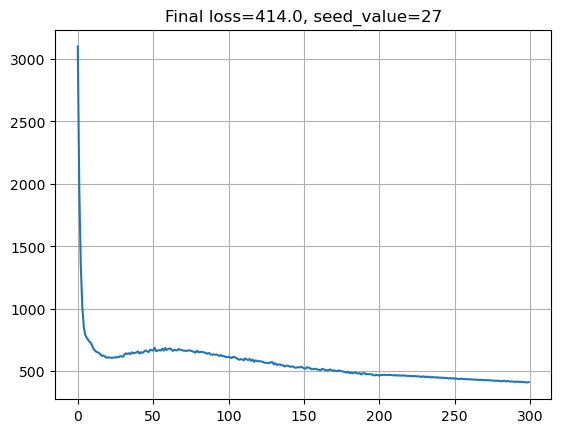

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)


100%|██████████| 300/300 [01:14<00:00,  4.00it/s]


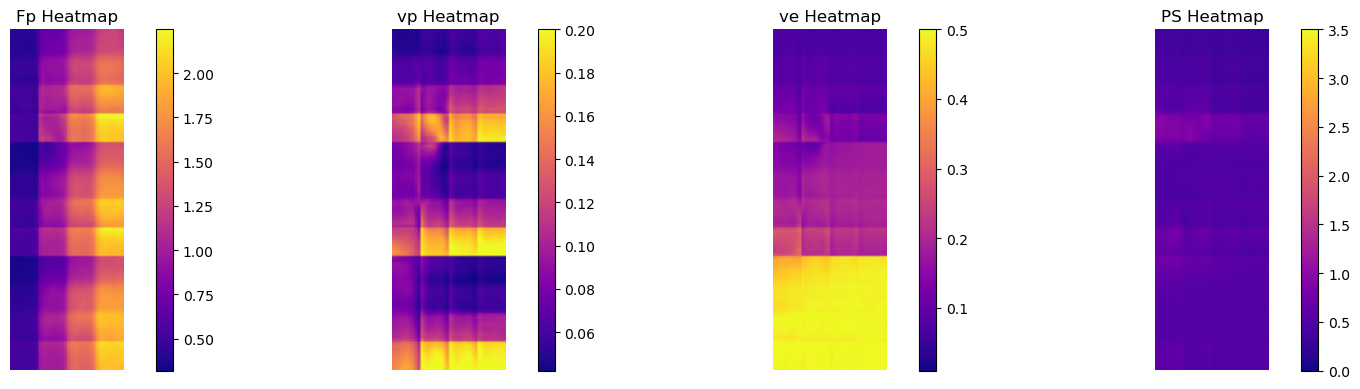

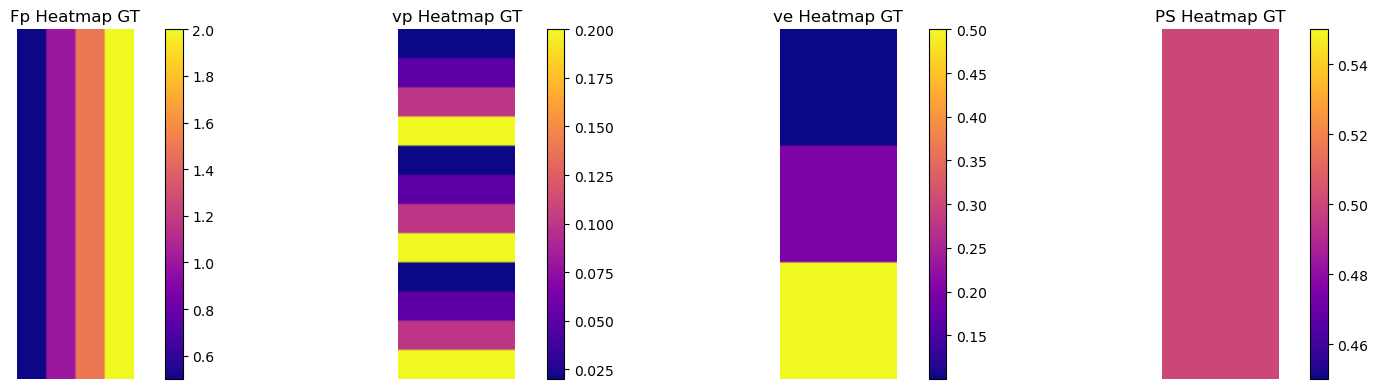

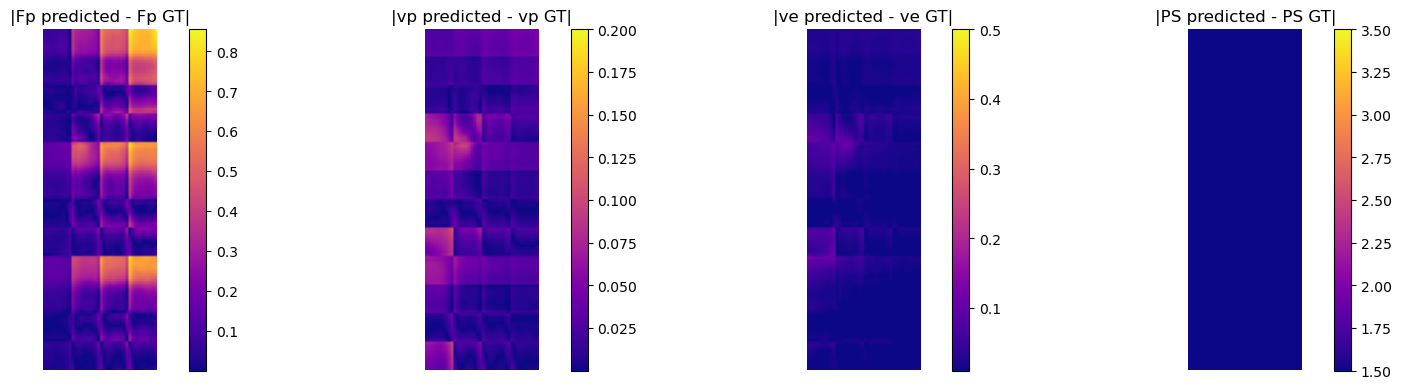

382.1180181503296


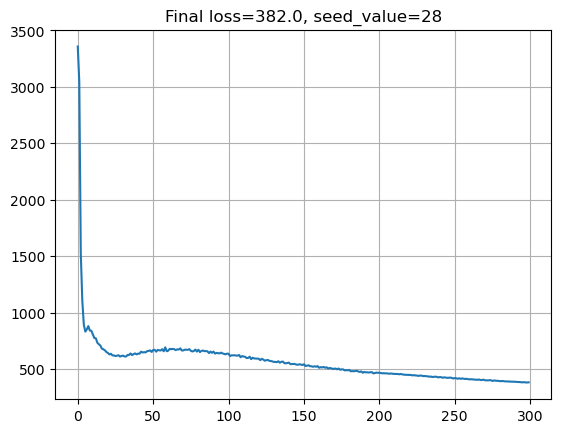

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)


100%|██████████| 300/300 [01:14<00:00,  4.01it/s]


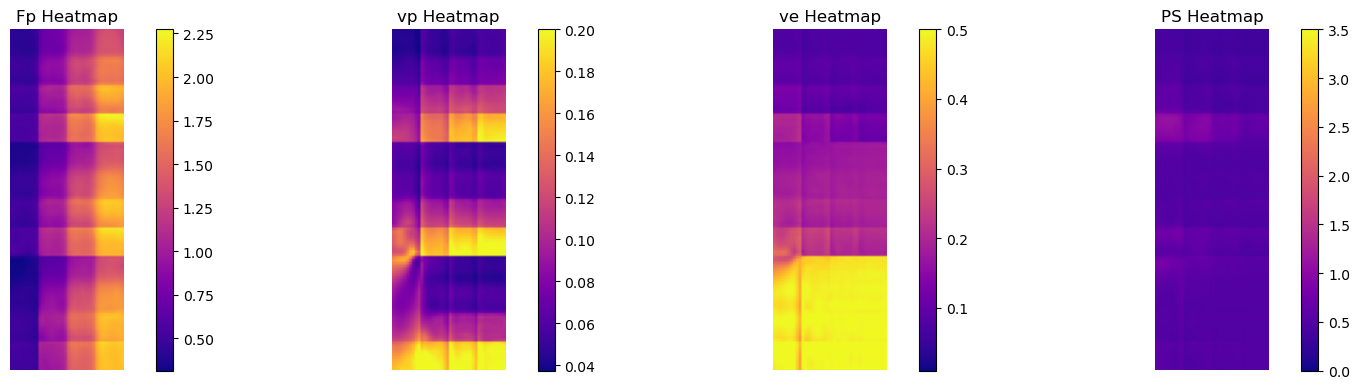

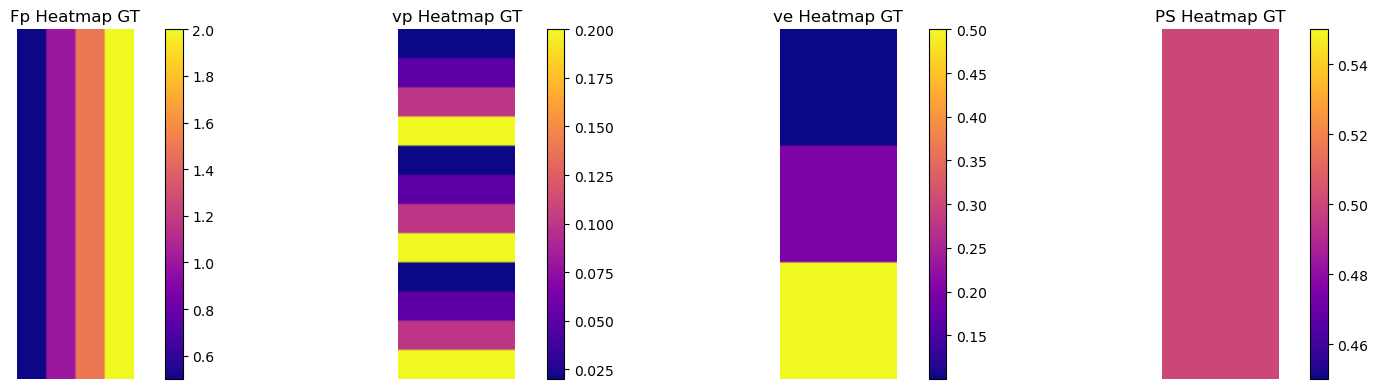

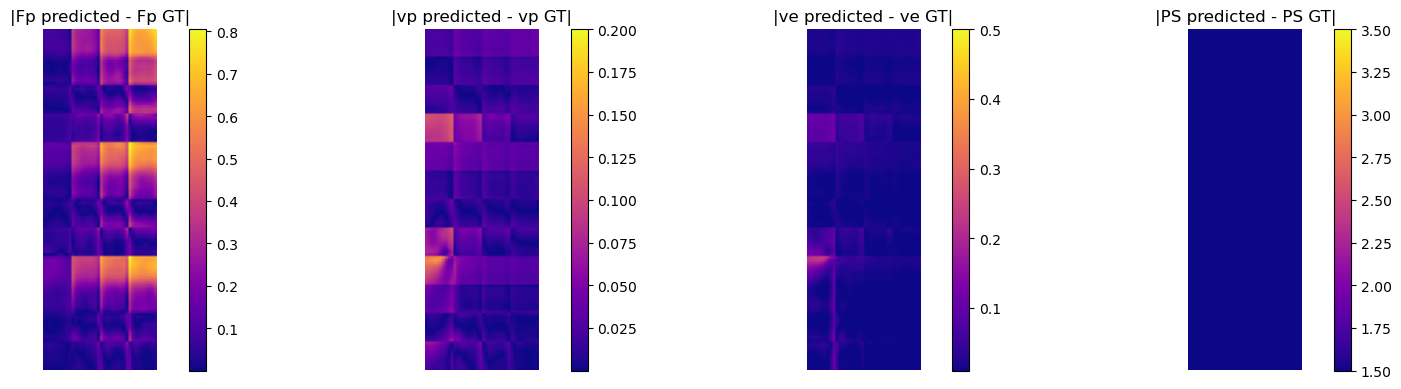

368.41869163513184


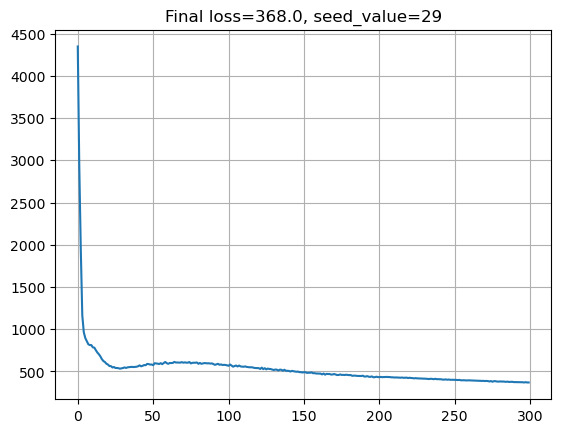

In [20]:
def main(seed_value, ps_slice, epochs):    
    t = time.time()
    # hard coded. later will add the config!
    aif_time, aif, myo_curves, myo_pars = make_dro_no_delay(tf_format=-1, ps_slice=ps_slice, snr=17.5) # type: ignore
    model_aif, model_e, model_p, model_ode, total_losses, cost_list = train_pinn(myo_curves, myo_pars, aif_time, aif, 
            epochs=epochs, lr=3e-5, batch_size=512, seed_value=seed_value,
            num_layers_aif=5, dim_hidden_aif=64, w0_aif=25, w0_initial_aif=15,
            num_layers_myo=5, dim_hidden_myo = 128, w0_myo=20, w0_initial_myo=25,
            num_layers_conv=5, dim_hidden_conv=512, w0_conv=10, w0_initial_conv=20,
            loss_w_aif=5.0, loss_w_myo = 10.0, loss_w_conv=10.0,
    ) #added two last losses
    
    return model_aif, model_e, model_p, model_ode, total_losses, cost_list

ps_slice=0
seed_value = 25
epochs = 300
final_loss = np.zeros(shape=(10, 3)) # 3 : 300 epochs (30, 100, 300)

i = 0
for seed_value in np.arange(20, 30):
    model_aif, model_e, model_p, model_ode, total_losses, cost_list = main(seed_value, ps_slice, epochs)

    cost_sum = np.sum(np.array(cost_list), axis=1) # Fp+ve+vp+ps losses
    plt.plot(cost_sum)
    print(cost_sum[-1])
    plt.grid()
    plt.title("Final loss={}, seed_value={}".format(np.around(cost_sum[-1], 0), seed_value))
    plt.show()

    final_loss[i][0] = cost_sum[29]
    final_loss[i][1] = cost_sum[99]
    final_loss[i][2] = cost_sum[299]
    #final_loss[seed_index][3] = cost_sum[999]
    #final_loss[seed_index][4] = cost_sum[2999]

    i += 1

[[544.04372406 590.08090258 396.06908369]
 [558.62741661 543.78375816 374.72574902]
 [560.63686752 609.04340219 407.11694527]
 [574.50737667 607.27820873 413.92919493]
 [537.72228909 554.39290094 383.82895756]
 [515.42908955 574.25940132 398.68213463]
 [598.86307716 575.91281223 384.78086948]
 [620.27009964 613.55166578 413.61390877]
 [615.69736004 636.44112778 382.11801815]
 [535.53490257 571.30219364 368.41869164]]


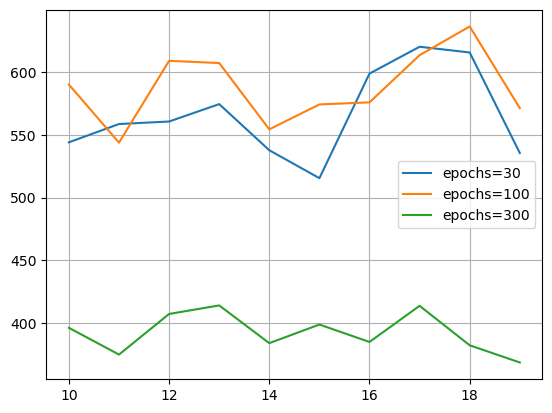

In [21]:
print(final_loss)

seed_values = np.arange(10, 20)
labels = ["epochs=30", "epochs=100", "epochs=300"]
i = 0
for elt in final_loss.T:
    plt.plot(seed_values, elt, label=labels[i])
    i+= 1
plt.grid()
plt.legend()
plt.show()

In [25]:
def round_sig(x, n=3):
    return float(f"{x:.{n}g}")

<>:19: SyntaxWarning: invalid escape sequence '\m'
<>:20: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\m'
<>:19: SyntaxWarning: invalid escape sequence '\m'
<>:20: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\m'
C:\Users\beren\AppData\Local\Temp\ipykernel_25624\656155935.py:19: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(seed_values, fl_30, label="epochs=30, $\mu$={}, cv={}".format(mu_30, cv_30))
C:\Users\beren\AppData\Local\Temp\ipykernel_25624\656155935.py:20: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(seed_values, fl_100, label="epochs=100, $\mu$={}, cv={}".format(mu_100, cv_100))
C:\Users\beren\AppData\Local\Temp\ipykernel_25624\656155935.py:21: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(seed_values, fl_300, label="epochs=300, $\mu$={}, cv={}".format(mu_300, cv_300))


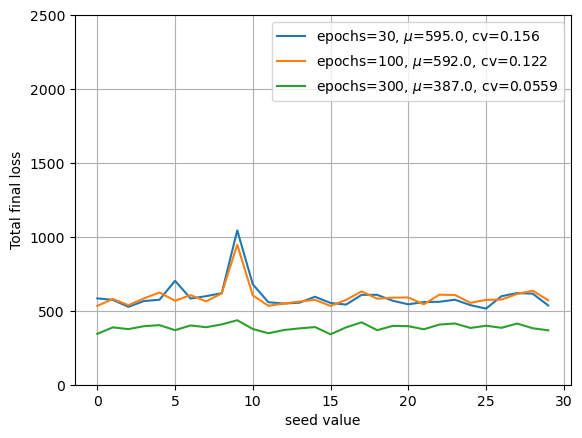

In [ ]:
#DATA: 2A; conv loss with Huber criterion and Adam optimizer

fl_30 = [584, 574, 527, 566, 575, 703, 583, 599, 619, 1044 ,679, 558, 549, 555, 595, \
            553, 542, 608, 608, 568, 544, 559, 561, 575, 538, 515, 599, 620, 616, 536]
fl_100 = [533, 580, 538, 584, 624, 568, 606, 564, 618, 947, 604, 534, 549, 563, 574, \
            533, 574, 631, 582, 589, 590, 544, 609, 607, 554, 574, 576, 614, 636, 571]
fl_300 = [344, 388, 376, 396, 403, 369, 401, 389, 408, 436, 377, 348, 370, 381, 390, \
            341, 388, 422, 369, 398, 396, 375, 407, 414, 384, 399, 385, 414, 382, 368]

mu_30 = round_sig(np.mean(fl_30))
mu_100 = round_sig(np.mean(fl_100))
mu_300 = round_sig(np.mean(fl_300))
cv_30 =  round_sig( np.std(fl_30)/np.abs(np.mean(fl_30)) )
cv_100 = round_sig( np.std(fl_100)/np.abs(np.mean(fl_100)) )
cv_300 = round_sig( np.std(fl_300)/np.abs(np.mean(fl_300)) )

seed_values = np.arange(0,30)

plt.plot(seed_values, fl_30, label="epochs=30, $\mu$={}, cv={}".format(mu_30, cv_30))
plt.plot(seed_values, fl_100, label="epochs=100, $\mu$={}, cv={}".format(mu_100, cv_100))
plt.plot(seed_values, fl_300, label="epochs=300, $\mu$={}, cv={}".format(mu_300, cv_300))

plt.grid()
plt.legend()
plt.ylim(0,2500)
plt.xlabel("seed value")
plt.ylabel("Total final loss")
plt.show()

# end

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)


100%|██████████| 300/300 [01:44<00:00,  2.86it/s]


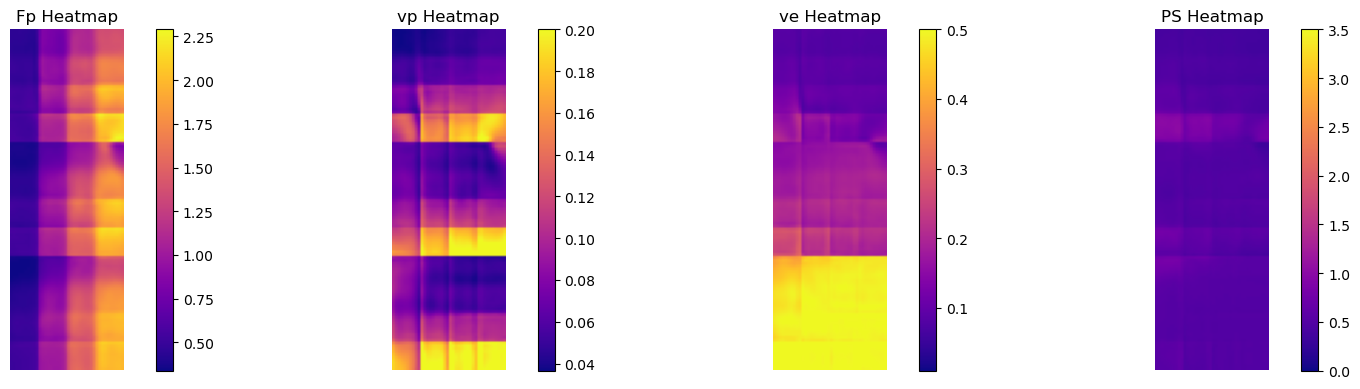

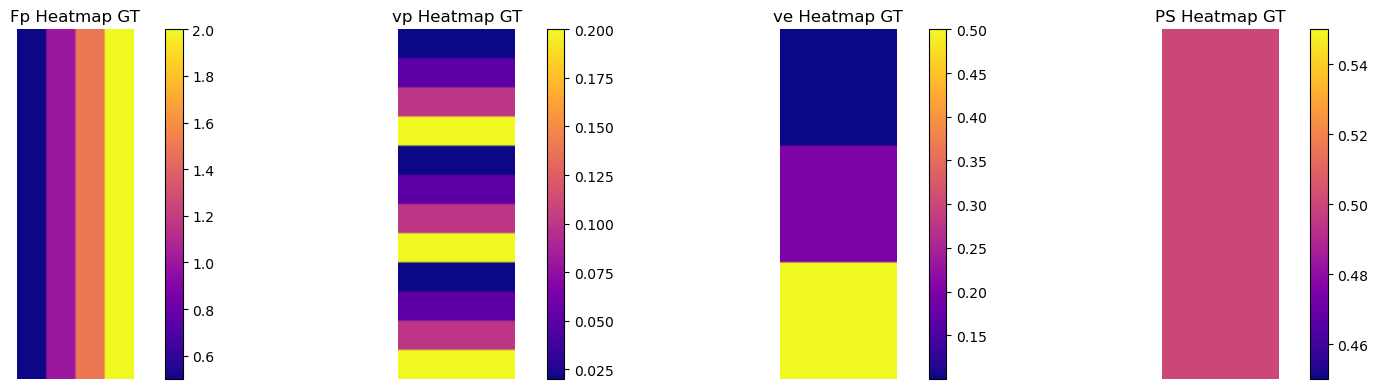

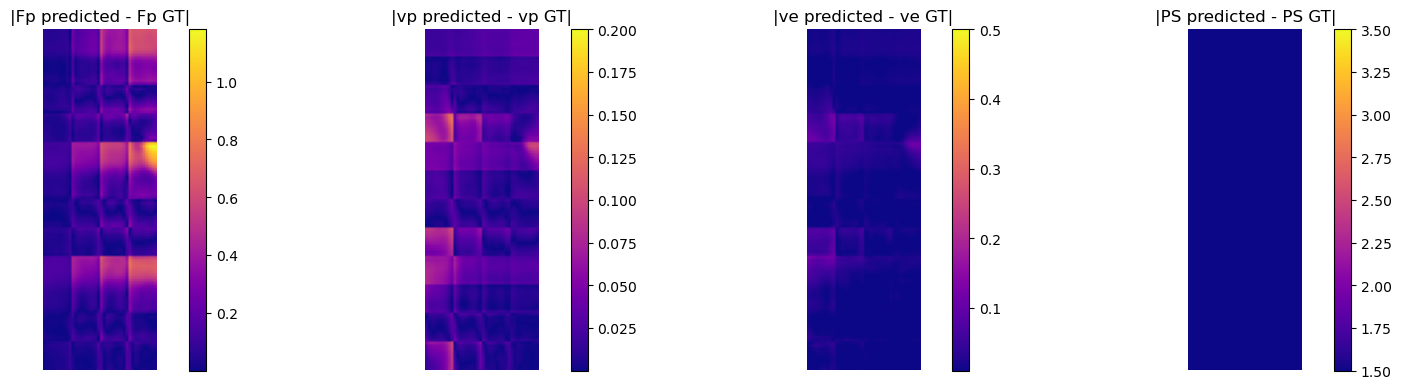

Shape of myo_curves: (100, 40, 120, 1)
Shape of myo_pars: (40, 120, 1, 4)


  7%|▋         | 20/300 [00:07<01:44,  2.67it/s]


KeyboardInterrupt: 

In [ ]:
# redundant tuning cell

def main(seed_value, ps_slice, loss_w_ode, epochs):    
    t = time.time()
    # hard coded. later will add the config!
    aif_time, aif, myo_curves, myo_pars = make_dro_no_delay(tf_format=-1, ps_slice=ps_slice, snr=17.5) # type: ignore
    model_aif, model_e, model_p, model_ode, total_losses, cost_list = train_pinn(myo_curves, myo_pars, aif_time, aif, 
            epochs=epochs, lr=3e-5, batch_size=512, seed_value=seed_value,
            num_layers_aif=5, dim_hidden_aif=64, w0_aif=25, w0_initial_aif=15,
            num_layers_myo=5, dim_hidden_myo = 128, w0_myo=20, w0_initial_myo=25,
            num_layers_conv=5, dim_hidden_conv=512, w0_conv=10, w0_initial_conv=20,
            loss_w_aif=5.0, loss_w_myo = 10.0, loss_w_ode = loss_w_ode, loss_w_conv=10.0,
    ) #added two last losses
    
    # # save models
    # torch.save(model_aif.state_dict(), "model_aif.pth")
    # torch.save(model_myo.state_dict(), "model_myo.pth")
    # torch.save(model_ode.state_dict(), "model_ode.pth")
    return model_aif, model_e, model_p, model_ode, total_losses, cost_list

ps_slice=0
seed_value = 25
loss_w_ode = 0.0
epochs = 300

seed_min = 0
seed_max = 3
final_loss = np.zeros(shape=(seed_max-seed_min, 3)) # 3 : 300 epochs (30, 100, 300)

for seed_index in np.arange(0, seed_max-seed_min):
    seed_value = seed_min+seed_index
    model_aif, model_e, model_p, model_ode, total_losses, cost_list = main(seed_value, ps_slice, loss_w_ode, epochs)

    cost_sum = np.sum(np.array(cost_list), axis=1) # Fp+ve+vp+ps losses

    #epochs = 30, 100
    #final_loss[seed_value][0] = cost_sum[9]
    final_loss[seed_index][0] = cost_sum[29]
    final_loss[seed_index][1] = cost_sum[99]
    final_loss[seed_index][2] = cost_sum[299]
    #final_loss[seed_index][3] = cost_sum[999]
    #final_loss[seed_index][4] = cost_sum[2999]
    
    # cost_sum = np.sum(np.array(cost_list), axis=1)

    # plt.plot(cost_sum)

    # x_data = np.arange(80, 100)
    # y_data = cost_sum[x_data]

    # plt.scatter(x_data, y_data)

    # from scipy.optimize import curve_fit

    # def L(t, alpha, c, k):
    #     return c + k * np.exp(-alpha*t)

    # popt, pcov = curve_fit(L, x_data, y_data, p0 = [0.015, 1000, 3000])

    # plt.plot(x_data, L(x_data, popt[0], popt[1], popt[2]))

    # plt.scatter(x_data, y_data)
    # plt.show()


(300,)
343.556440114975


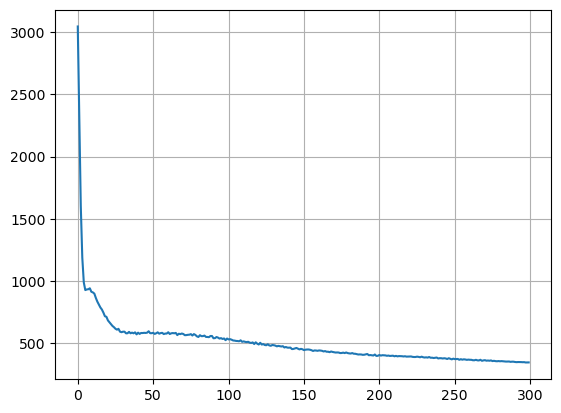

In [13]:
print(cost_sum.shape)
plt.plot(cost_sum)
print(cost_sum[-1])
plt.grid()

[[587. 536. 344.]
 [  0.   0.   0.]
 [  0.   0.   0.]]


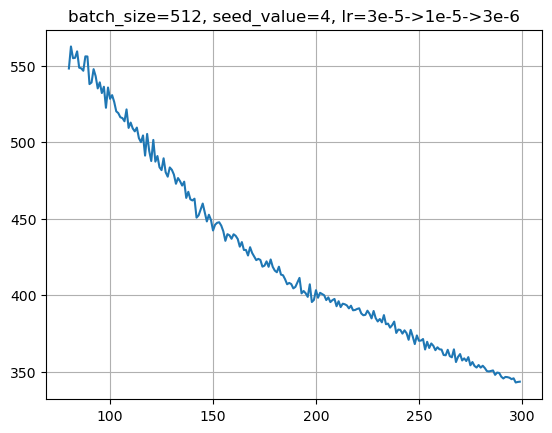

In [14]:
print(np.around(final_loss, 0))
y_data = cost_sum

plt.plot(np.arange(80, len(cost_sum[80:])+80), cost_sum[80:])
plt.title("batch_size=512, seed_value=4, lr=3e-5->1e-5->3e-6")
plt.grid()

In [15]:
print(np.around(final_loss.T[0].astype(int)))
print(np.around(final_loss.T[1].astype(int)))
print(np.around(final_loss.T[2].astype(int)))

def round_sig(x, n=3):
    return float(f"{x:.{n}g}")

[586   0   0]
[535   0   0]
[343   0   0]


C:\Users\beren\AppData\Local\Temp\ipykernel_14612\2451640141.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


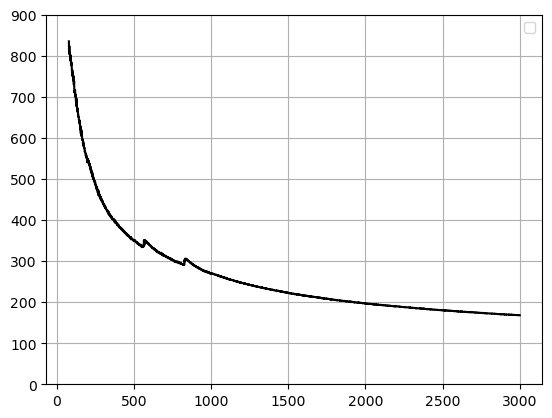

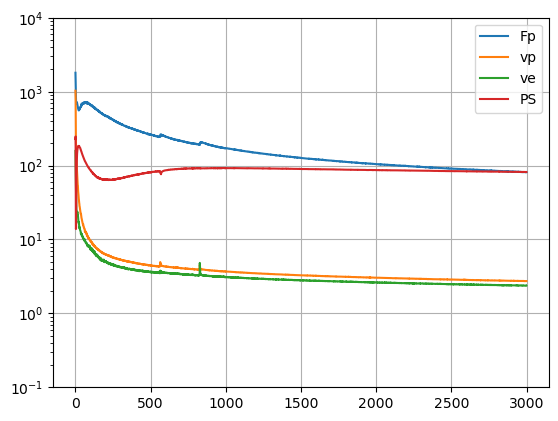

168.04413557052612


In [19]:
cost_sum = np.sum(np.array(cost_list), axis=1)
#plt.plot(cost_sum, color="black")
plt.plot(np.arange(80, len(cost_sum[80:])+80), cost_sum[80:], color="black")
plt.legend()
plt.grid()
plt.ylim(0,900)
plt.show()

labels = ["Fp", "vp", "ve", "PS"] 
i = 0
for list in cost_list.T:
    plt.plot(list, label=labels[i])
    i += 1
plt.yscale("log")
plt.ylim(1e-1, 1e4)
plt.legend()
plt.grid()
plt.show()

print(np.sum(cost_list[-1]))

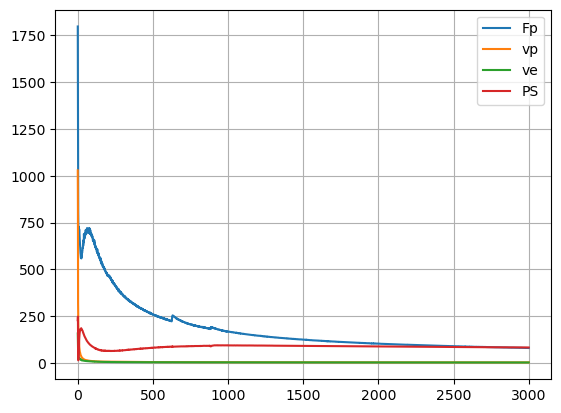

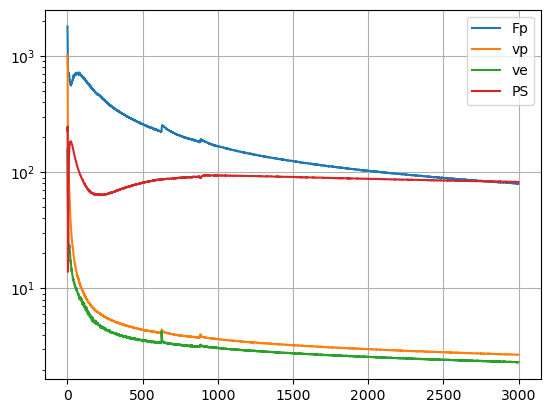

167.02049469947815


In [13]:
labels = ["Fp", "vp", "ve", "PS"] 
i = 0
for list in cost_list.T:
    plt.plot(list, label=labels[i])
    i += 1
plt.legend()
plt.grid()
plt.show()

labels = ["Fp", "vp", "ve", "PS"] 
i = 0
for list in cost_list.T:
    plt.plot(list, label=labels[i])
    i += 1
plt.yscale("log")
plt.legend()
plt.grid()
plt.show()

print(np.sum(cost_list[-1]))

In [ ]:
#####################3 model losses saving

#np.save("cost_sum_4_3000_512_smooth.npy", y_data)

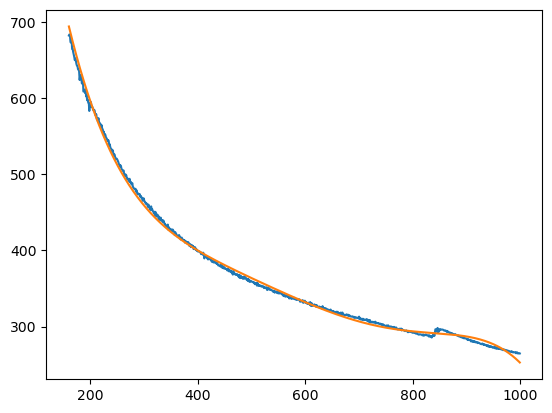

In [ ]:
def L(t, alpha, c, k):
        return c + k * np.exp(-alpha*t)
p0_L = [0.015, 1000, 3000]
def L2(t, c, k, a, beta):
    return c + k * np.exp(-(a * t)**beta)
p0_L2 = [250, 3000, 0.015, 0.7]
def L3(t, y0, t0, a, m):
    return y0 - m*(t - t0)**(1/a)
p0_L3 = [1000, 80, 2, 30]
def poly(t, a, b, c, d, e, f):
     return a + b*t + c*t**2 + d*t**3 + e*t**4 + f * t**5
p0_poly = [250, -1, -10, 1, 1, 1]
x = np.arange(80, 1000)
y = y_data[80:]

from scipy.optimize import curve_fit

popt, pcov = curve_fit(
    poly,
    x,
    y,
    p0=p0_poly,
)

plt.plot(x[80:], y[80:])
plt.plot(x[80:], poly(x, popt[0], popt[1], popt[2], popt[3], popt[4], popt[5])[80:])

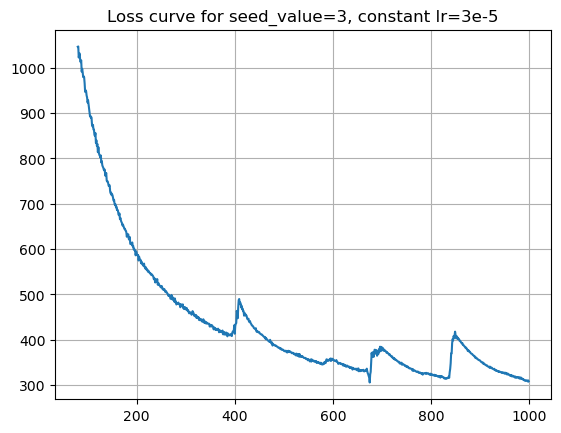

In [ ]:
# for exposing sawtooth wave pattern

cost_sum_4 = np.load("cost_sum_3_1000_512.npy")

y_data = cost_sum_4

plt.plot(np.arange(80, len(y_data[80:])+80), y_data[80:])
plt.title("Loss curve for seed_value=3, constant lr=3e-5")
plt.grid()

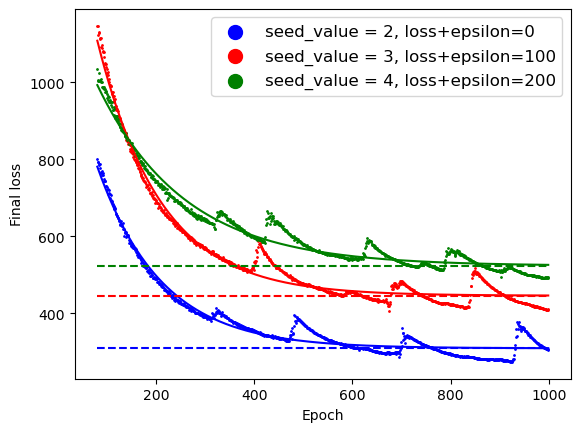

In [ ]:
############### epsilon plot

cost_sum_2 = np.load("cost_sum_2_1000_512.npy")
cost_sum_3 = np.load("cost_sum_3_1000_512.npy")
cost_sum_4 = np.load("cost_sum_4_1000_512.npy")
cost_sum_set = [cost_sum_2, cost_sum_3, cost_sum_4]
color_set = ["blue", "red", "green"]

epsilon = 100
for ind in np.arange(0,3):
    y_data = cost_sum_set[ind][80:]
    x_data = np.arange(0, len(y_data)) + 80
    plt.scatter(x_data, y_data + ind*epsilon, color=color_set[ind], s=1, 
                label="seed_value = {}, loss+epsilon={}".format(2+ind, epsilon*ind))

    def L(t, alpha, c, k):
        return c + k * np.exp(-alpha*t)

    popt, pcov = curve_fit(L, x_data, y_data, p0 = [0.015, 1000, 3000])

    plt.plot(x_data, L(x_data, popt[0], popt[1], popt[2])+ind*epsilon, color=color_set[ind])

    plt.plot([x_data[0], x_data[-1]], [popt[1]+ind*epsilon, popt[1]+ind*epsilon], linestyle="--", color=color_set[ind])

plt.legend(markerscale=10, fontsize=12)
plt.xlabel("Epoch")
plt.ylabel("Final loss")
plt.show()
    

In [ ]:
print(popt)

[1.93240053e-02 4.52470821e+02 2.45298218e+03]


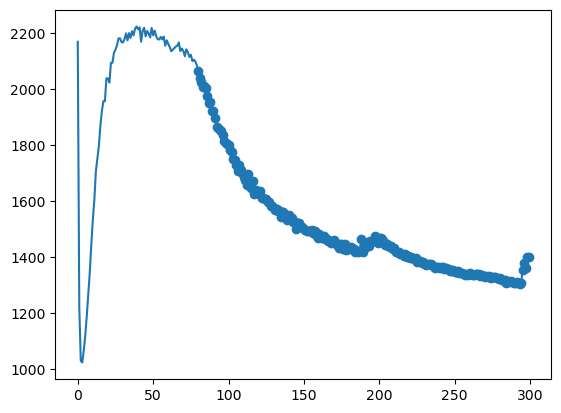

In [ ]:
cost_sum = np.sum(np.array(cost_list), axis=1)

plt.plot(cost_sum)

x_data = np.arange(80, 300)
y_data = cost_sum[x_data]

plt.scatter(x_data, y_data)

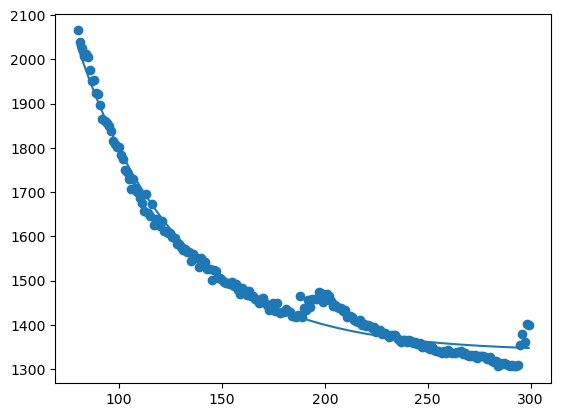

In [ ]:
from scipy.optimize import curve_fit

def L(t, alpha, c, k):
    return c + k * np.exp(-alpha*t)

popt, pcov = curve_fit(L, x_data, y_data, p0 = [0.015, 1000, 3000])

plt.plot(x_data, L(x_data, popt[0], popt[1], popt[2]))

plt.scatter(x_data, y_data)
plt.show()

# Epsilon plot end here

In [ ]:
seed_values = np.arange(10, 40)

fl_30 = [2174.85052109, 1718.53709221, 1756.21317101, 1128.64660645, 1678.07248688, 1915.58394241, 1503.31450081, 
         1172.30664635, 2132.95944595, 936.89330196, 1009.01616096, 1688.163908, 1932.81077003, 1976.22146988, 
         2057.31811905, 751.52515507, 1952.78017426, 1815.1165123, 1118.79101562, 898.78807259, 1283.07074928, 
         1531.24822998, 1312.23288345, 1593.91981125, 2176.68587112, 1960.55641556, 1235.39776421, 1475.31562996,
           1556.41758347, 1094.900238040]
fl_100 = [1816.37981796, 1361.12882423, 1380.97376728, 660.43295097, 1326.45242882, 1381.27276039, 1280.38038254, 
          679.48173332, 1798.88397598, 607.05668926, 624.50019979, 1357.62481689, 1504.68316364, 1488.04299641, 
          2091.13491821, 598.82614899, 1381.11494637, 1330.73468542, 666.3400631, 589.26685095, 970.80098724, 
          1232.74098587, 1002.48580265, 1281.10715389, 1791.06262779, 1559.13994026, 933.30466652, 1271.71178436, 
          1259.76792669, 624.33000898]
fl_300 = [1351.58122158, 1090.427526, 1126.5374136, 412.10630322, 1156.6332922, 1172.93819904, 1082.95396781, 
          426.89445639, 1163.884974, 427.87793064, 463.51944828, 1097.9771328, 1162.97265244, 1174.6751585, 
          1197.76004601, 382.79889584, 1083.54032469, 1057.12874031, 367.89570999, 431.03493023, 455.31325626, 
          551.18302345, 444.49038601, 943.78087902, 1238.63262177, 1192.540977, 544.3891964, 786.04391098, 
          994.06250906, 402.4422245]

plt.plot(seed_values, fl_30, label="epochs=30")
plt.plot(seed_values, fl_100, label="epochs=100" )
plt.plot(seed_values, fl_300, label="epochs=300")

plt.legend()
plt.grid()
plt.xlabel("seed value")
plt.ylabel("Total final cost")
plt.ylim((0, 3000))
plt.xticks(np.arange(10, 41, 4))
plt.show()

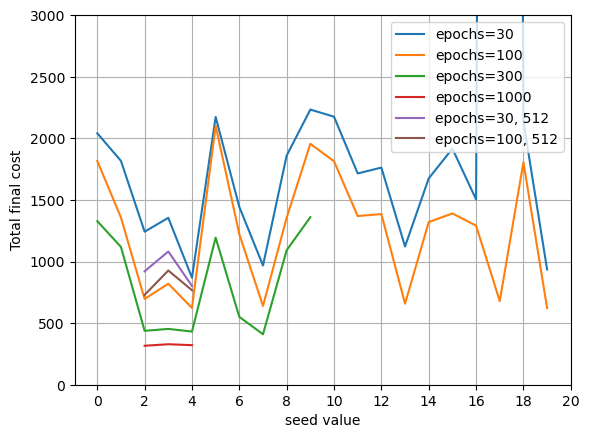

In [ ]:
################### 0 -> 9
seed_values_09 = np.arange(0, 10)
#final losses for seed values ind_start to ind_end; for different amount of epochs 
fl_09_30 = [2041.0342865, 1817.16262817, 1242.08413696, 1354.82438278, 868.68933773, 2173.71059036, 1443.17158699, 
 967.76900673, 1860.00162888, 2233.49024582]
fl_09_100 = [1816.25112915, 1357.7066021, 696.05937767, 819.69483185, 623.55674791, 2101.42475891, 1221.73070765,
 639.43999147, 1355.80723572, 1955.44471359]

#################### 10 -> 19
seed_values_1019 = np.arange(10, 20)
fl_1019_30 = [2175.31947708, 1714.9962368, 1762.28892136, 1122.32619476, 1674.9864006, 1916.16172409, 1503.8421278, 
              41175.31441307, 2135.32325745, 935.67053986]
fl_1019_100 = [1813.71325874, 1369.09678745, 1385.09143639, 657.89869833, 1320.25049257, 1390.22990227, 1291.18359041, 
               678.79915285, 1805.42628288, 622.24767542]

################## extra: 300 epochs for seed values 0-> 9
seed_values_extra = np.arange(0, 10)
fl_09_300 = [1328.03604698, 1118.44868326, 437.37966967, 452.99571276, 431.74449158, 1193.92588806, 550.72154903,
            409.59411526, 1091.97665167, 1359.91154289]

################ extra_2: 1000 epochs for seed values 2 -> 4
seed_values_extra_2 = np.arange(2, 5)
fl_24_1000 = [ 316.28596449,  328.60443377,  321.14710283]

################### concatenating lists into single array
seed_values = []
for list_ in [seed_values_09, seed_values_1019]:
    for elt in list_:
        seed_values.append(elt)
fl_30_full = []
for list_ in [fl_09_30, fl_1019_30]:
    for elt in list_:
        fl_30_full.append(elt)
fl_100_full = []
for list_ in [fl_09_100, fl_1019_100]:
    for elt in list_:
        fl_100_full.append(elt)

###################### adding batch size 512 plots

seed_values_512 = [2,3,4]
fl_24_30_512 = [ 920.33959389, 1081.44276428, 802.0500536 ]
fl_24_100_512 = [ 729.18639851,  926.94294739,  767.29029942]

#################### finishing plot

plt.plot(seed_values, fl_30_full, label="epochs=30")
plt.plot(seed_values, fl_100_full, label="epochs=100" )
plt.plot(seed_values_extra, fl_09_300, label="epochs=300")
plt.plot(seed_values_extra_2, fl_24_1000, label="epochs=1000")
plt.plot(seed_values_512, fl_24_30_512, label="epochs=30, 512")
plt.plot(seed_values_512, fl_24_100_512, label="epochs=100, 512")

plt.legend()
plt.grid()
plt.xlabel("seed value")
plt.ylabel("Total final cost")
plt.ylim((0, 3000))
plt.xticks(np.arange(0, 21, 2))
plt.show()

# End of sweep segment

In [ ]:
loss_w_ode_set = [1.0, 0.1, 0.01, 0.001, 0.0001, 1e-5, 1e-6, 1e-7, 1e-8, 1e-9, 1e-10]
final_loss_set = [1557, 1245, 1046, 827, 653, 606, 601, 599, 604, 596, 604]

plt.plot(loss_w_ode_set, final_loss_set)
plt.xscale("log")
plt.xlabel("loss_w_ode")
plt.ylabel("Final loss")
plt.title("epochs=100, seed=25, lr=3e-5")
plt.grid()

In [ ]:
for i in np.arange(0, 4):
    print(cost_T[i][-1])

In [ ]:
def main(ps_slice):    
    t = time.time()
    # hard coded. later will add the config!
    aif_time, aif, myo_curves, myo_pars = make_dro_no_delay(tf_format=-1, ps_slice=ps_slice, snr=17.5) # type: ignore
    model_aif, model_e, model_p, model_ode, total_losses, cost_list = train_pinn(myo_curves, myo_pars, aif_time, aif, 
            epochs=100, lr=3e-5, batch_size=256,
            num_layers_aif=5, dim_hidden_aif=64, w0_aif=25, w0_initial_aif=15,
            num_layers_myo=5, dim_hidden_myo = 128, w0_myo=20, w0_initial_myo=25,
            num_layers_2cxm=5, dim_hidden_2cxm=512, w0_2cxm=10, w0_initial_2cxm=20,
            loss_w_aif=5.0, loss_w_myo = 10.0, loss_w_ode = 0.01, loss_w_conv=10.0) #added two last losses
    
    # # save models
    # torch.save(model_aif.state_dict(), "model_aif.pth")
    # torch.save(model_myo.state_dict(), "model_myo.pth")
    # torch.save(model_ode.state_dict(), "model_ode.pth")
    return model_aif, model_e, model_p, model_ode, total_losses, cost_list


# if __name__ == "__main__":
#     main()

ps_slice_set = [0, 1, 2] #0.5, 1.5, 2.5

for ps_slice in ps_slice_set:
    model_aif, model_e, model_p, model_ode, total_losses, cost_list  = main(ps_slice)
    cost_T = cost_list.T
    Fp, vp, ve, PS_ = cost_T[0], cost_T[1], cost_T[2], cost_T[3]

    plt.plot(Fp, label= "Fp")
    plt.plot(vp, label="vp")
    plt.plot(ve, label="ve")
    plt.plot(PS_, label="PS")

    plt.legend()
    plt.title("epochs={}, lr=3e-5".format(len(Fp)))
    plt.ylim((0, np.max(cost_list)))  #plt.ylim((0, np.max(cost_list[5])))
    plt.grid()
    plt.show()

    print("Final loss: ", np.around(cost_T[0][-1] + cost_T[1][-1] + cost_T[2][-1] + cost_T[3][-1]))

    i = np.argmin(cost_T[0]+cost_T[1]+cost_T[2]+cost_T[3])

    print("Min loss: ", np.around(cost_T[0][i] + cost_T[1][i] + cost_T[2][i] + cost_T[3][i]))

    print("Lowest point epoch: ", i)

In [ ]:
print(cost_T.shape)

In [ ]:
def main():    
    t = time.time()
    # hard coded. later will add the config!
    aif_time, aif, myo_curves, myo_pars = make_dro_no_delay(tf_format=-1, ps_slice=0, snr=17.5) # type: ignore
    model_aif, model_e, model_p, model_ode, total_losses, cost_list = train_pinn(myo_curves, myo_pars, aif_time, aif, 
            epochs=300, lr=3e-5, batch_size=256,
            num_layers_aif=5, dim_hidden_aif=64, w0_aif=25, w0_initial_aif=15,
            num_layers_myo=5, dim_hidden_myo = 128, w0_myo=20, w0_initial_myo=25,
            num_layers_2cxm=5, dim_hidden_2cxm=512, w0_2cxm=10, w0_initial_2cxm=20,
            loss_w_aif=5.0, loss_w_myo = 10.0, loss_w_ode = 0.01, loss_w_conv=10.0) #added two last losses
    
    # # save models
    # torch.save(model_aif.state_dict(), "model_aif.pth")
    # torch.save(model_myo.state_dict(), "model_myo.pth")
    # torch.save(model_ode.state_dict(), "model_ode.pth")
    return model_aif, model_e, model_p, model_ode, total_losses, cost_list


# if __name__ == "__main__":
#     main()

ps_slice_set = [0, 1, 2] #0.5, 1.5, 2.5

model_aif, model_e, model_p, model_ode, total_losses, cost_list  = main()

# Here

In [ ]:
aif_time, aif, myo_curves, myo_pars = make_dro_no_delay(-1, 0, 17.5) # type: ignore

print(myo_curves.shape)

In [ ]:
# visualize GT only

# get same DRO as model is trained on
aif_time, aif, myo_curves, myo_pars = make_dro_no_delay(-1, 0, 17.5) # type: ignore

T, H, W, _ = myo_curves.shape

frames = []
for t in np.arange(0, 100):
    frame1 = myo_curves[t, :, :, 0].T

    frame1 = (frame1 - np.min(frame1)) / (np.max(frame1) - np.min(frame1))
    p1, p99 = np.percentile(frame1, [1, 99])
    frame1_norm = (frame1 - p1) / (p99 - p1)
    frame1_norm = np.clip(frame1_norm, 0, 1)

    frames.append(frame1_norm)

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots()
im = ax.imshow(frames[1], cmap='gray', animated=True) #must not be frame 0
ax.axis('off')

def update(frame):
    im.set_array(frame)
    return [im]

ani = FuncAnimation(
    fig,
    update,
    frames=frames,
    interval=100,   # ms between frames
    blit=True
)

# Prevent first frame from showing below GIF
plt.close(fig)

# Display inline in notebook
HTML(ani.to_jshtml())

ani.save(
    "GT_DRO.gif"
    #writer=PillowWriter(fps=10)
)

In [ ]:
# visualize comparison between: e+p vs GT

aif_time, aif, myo_curves, myo_pars = make_dro_no_delay(-1, 0, 17.5) # type: ignore

i_x, i_y = 30, 30

frames1 = []
frames2 = []

for t in np.arange(0, 100):

    frame1 = myo_curves[t, :, :, 0].T

    frame1 = (frame1 - np.min(frame1)) / (np.max(frame1) - np.min(frame1))
    p1, p99 = np.percentile(frame1, [1, 99])
    frame1_norm = (frame1 - p1) / (p99 - p1)
    frame1_norm = np.clip(frame1_norm, 0, 1)

    frame2 = myo_curves[:,i_x,i_y,0]

    frames1.append(frame1)
    frames2.append(frame2)

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

im1 = axes[0].imshow(frames1[1], cmap='gray', animated=True)
im2 = axes[1].plot(frames2[1], animated=True)

axes[0].set_title("myo_curves (GT)")
axes[1].set_title("myo_curve")

for ax in axes:
    ax.axis("off")

def update(i):
    im1.set_array(frames1[i])
    im2.set_data(frames2[i])
    return [im1, im2]

print(type(im1))
print(type(im2))

ani = FuncAnimation(
    fig,
    update,
    frames=len(frames1),
    interval=100,
    blit=True
)

# Prevent first frame from showing below GIF
plt.close(fig)

HTML(ani.to_jshtml())

# ani.save(
#     "animation_v1_total_vs_GT_epochs_300.gif",
#     writer=PillowWriter(fps=10)
# )

The above cell shows the predicted perfusion parameter maps, the Ground Truth, and the absolute difference between them. For epochs=1000, the highest inaccuracy shows in Fp and this inaccuracy is mainly the inability to reproduce the high frequency patttern (thin lines around some pf the 10x10 compartments).

The below cell shows the contributed fractions of the four perfusion parameters to the total loss. Notice how Fp loss dominates.

In [ ]:
cost_T = cost_list.T
Fp, vp, ve, PS_ = cost_T[0], cost_T[1], cost_T[2], cost_T[3]

plt.plot(Fp, label= "Fp")
plt.plot(vp, label="vp")
plt.plot(ve, label="ve")
plt.plot(PS_, label="PS")

plt.legend()
plt.title("epochs={}, lr=3e-5".format(len(Fp)))
plt.ylim((0, np.max(cost_list)))  #plt.ylim((0, np.max(cost_list[5])))
plt.grid()
plt.show()

print("Final loss: ", np.around(cost_T[0][-1] + cost_T[1][-1] + cost_T[2][-1] + cost_T[3][-1]))

i = np.argmin(cost_T[0]+cost_T[1]+cost_T[2]+cost_T[3])

print("Min loss: ", np.around(cost_T[0][i] + cost_T[1][i] + cost_T[2][i] + cost_T[3][i]))

print("Lowest point epoch: ", i)

In [ ]:
#cgpt:

@torch.no_grad()
def predict_myo_curves(model_myo, aif_time, H, W, device, batch_size=65536):
    """
    Applies trained model_myo over the full [T, H, W] grid.

    Returns:
        pred_myo: np.ndarray with shape [T, H, W, 1]
    """

    model_myo.eval()

    T = len(aif_time)

    # Same coordinate construction used during training
    x = np.linspace(0, 1, H).astype(np.float32)
    y = np.linspace(0, 1, W).astype(np.float32)
    t_norm = np.linspace(0, 2, T).astype(np.float32)

    tt, xx, yy = np.meshgrid(t_norm, x, y, indexing="ij")

    coords_txy = np.stack([tt, xx, yy], axis=-1).reshape(-1, 3)
    X = torch.tensor(coords_txy, dtype=torch.float32).to(device)

    preds = []

    for i in range(0, X.shape[0], batch_size):
        X_batch = X[i:i + batch_size]

        t_input = X_batch[:, :1]      # [B, 1]
        xy_input = X_batch[:, 1:]     # [B, 2]

        pred = model_myo(t_input, xy_input)  # [B, 1]
        preds.append(pred.cpu())

    pred_myo = torch.cat(preds, dim=0)
    pred_myo = pred_myo.numpy().reshape(T, H, W, 1)

    return pred_myo

The below cell shows the fraction of contrast agent in extracellular fractional volume. Notice how halfway in the total time, the distribution of v_e over the DRO shows up.

In [ ]:
# visualize e

# get same DRO as model is trained on
aif_time, aif, myo_curves, myo_pars = make_dro_no_delay(-1, 0, 17.5) # type: ignore

T, H, W, _ = myo_curves.shape

myo_pred = predict_myo_curves(
    model_myo=model_e,
    aif_time=aif_time,
    H=H,
    W=W,
    device=device
)

print("Predicted myocardial curves shape:", myo_pred.shape)

frames = []
for t in np.arange(0, 100):
    frame_non_norm = myo_pred[t, :, :, 0].T
    frame = frame_non_norm * myo_pars[:,:,0,2].T
    frames.append((frame-np.min(frame))/(np.max(frame)-np.min(frame)))

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots()
im = ax.imshow(frames[1], cmap='gray', animated=True) #must not be frame 0
ax.axis('off')

def update(frame):
    im.set_array(frame)
    return [im]

ani = FuncAnimation(
    fig,
    update,
    frames=frames,
    interval=100,   # ms between frames
    blit=True
)

# Prevent first frame from showing below GIF
plt.close(fig)

# Display inline in notebook
HTML(ani.to_jshtml())

The below cell shows the fraction of contrast agent in plasma fractional volume. Notice how halfway in the total time, the distribution of v_p over the DRO shows up.

In [ ]:
# visualize p

# get same DRO as model is trained on
aif_time, aif, myo_curves, myo_pars = make_dro_no_delay(-1, 0, 17.5) # type: ignore

T, H, W, _ = myo_curves.shape

myo_pred = predict_myo_curves(
    model_myo=model_p,
    aif_time=aif_time,
    H=H,
    W=W,
    device=device
)

print("Predicted myocardial curves shape:", myo_pred.shape)

frames = []
for t in np.arange(0, 100):
    frame_non_norm = myo_pred[t, :, :, 0].T
    frame = frame_non_norm * myo_pars[:,:,0,1].T
    frames.append((frame-np.min(frame))/(np.max(frame)-np.min(frame)))

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots()
im = ax.imshow(frames[1], cmap='gray', animated=True) #must not be frame 0
ax.axis('off')

def update(frame):
    im.set_array(frame)
    return [im]

ani = FuncAnimation(
    fig,
    update,
    frames=frames,
    interval=100,   # ms between frames
    blit=True
)

# Prevent first frame from showing below GIF
plt.close(fig)

# Display inline in notebook
HTML(ani.to_jshtml())

The below cell shows total contrast agent over time, being the sum of contrast agent in plasma and in extracellular compartments.

In [ ]:
# visualize e+p

# get same DRO as model is trained on
aif_time, aif, myo_curves, myo_pars = make_dro_no_delay(-1, 0, 17.5) # type: ignore

T, H, W, _ = myo_curves.shape

myo_pred_p = predict_myo_curves(
    model_myo=model_p,
    aif_time=aif_time,
    H=H,
    W=W,
    device=device
)

myo_pred_e = predict_myo_curves(
    model_myo=model_e,
    aif_time=aif_time,
    H=H,
    W=W,
    device=device
)

print("Predicted myocardial curves shape:", myo_pred_e.shape)

frames = []
for t in np.arange(0, 100):
    frame_p_norm = myo_pred_p[t, :, :, 0].T * myo_pars[:,:,0,1].T
    frame_e_norm = myo_pred_e[t, :, :, 0].T * myo_pars[:,:,0,2].T
    frame = frame_p_norm + frame_e_norm
    frames.append((frame-np.min(frame))/(np.max(frame)-np.min(frame)))

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots()
im = ax.imshow(frames[1], cmap='gray', animated=True) #must not be frame 0
ax.axis('off')

def update(frame):
    im.set_array(frame)
    return [im]

ani = FuncAnimation(
    fig,
    update,
    frames=frames,
    interval=100,   # ms between frames
    blit=True
)

# Prevent first frame from showing below GIF
plt.close(fig)

# Display inline in notebook
HTML(ani.to_jshtml())

The below cell shows the total CA concentration on the left and the Ground Truth on the right. Notice how the GT seems to be reproduced but without the noise (SNR of 17.5)

In [ ]:
# visualize comparison between: e+p vs GT

frames1 = []
frames2 = []

for t in np.arange(0, 100):
    frame_p_norm = myo_pred_p[t, :, :, 0].T * myo_pars[:,:,0,1].T
    frame_e_norm = myo_pred_e[t, :, :, 0].T * myo_pars[:,:,0,2].T
    frame1 = frame_p_norm + frame_e_norm

    frame2 = myo_curves[t, :, :, 0].T

    frame1 = (frame1 - np.min(frame1)) / (np.max(frame1) - np.min(frame1))
    p1, p99 = np.percentile(frame1, [1, 99])
    frame1_norm = (frame1 - p1) / (p99 - p1)
    frame1_norm = np.clip(frame1_norm, 0, 1)

    frame2 = (frame2 - np.min(frame2)) / (np.max(frame2) - np.min(frame2))
    p1, p99 = np.percentile(frame2, [1, 99])
    frame2_norm = (frame2 - p1) / (p99 - p1)
    frame2_norm = np.clip(frame2_norm, 0, 1)

    frames1.append(frame1)
    frames2.append(frame2)

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

im1 = axes[0].imshow(frames1[1], cmap='gray', animated=True)
im2 = axes[1].imshow(frames2[1], cmap='gray', animated=True)

axes[0].set_title("myo_pred_p+myo_pred_p (prediction)")
axes[1].set_title("myo_curves (GT)")

for ax in axes:
    ax.axis("off")

def update(i):
    im1.set_array(frames1[i])
    im2.set_array(frames2[i])
    return [im1, im2]

ani = FuncAnimation(
    fig,
    update,
    frames=len(frames1),
    interval=100,
    blit=True
)

# Prevent first frame from showing below GIF
plt.close(fig)

HTML(ani.to_jshtml())

# ani.save(
#     "animation_v1_total_vs_GT_epochs_300.gif",
#     writer=PillowWriter(fps=10)
# )

The below cell shows the absolute value of the subtraction of the prediction by the ground truth. Notice how the result is (almost entirely) the white noise added to the GT.

In [ ]:
# visualize subtraction difference between pred and GT

frames = []

for t in np.arange(0, 100):
    frame_p_norm = myo_pred_p[t, :, :, 0].T * myo_pars[:,:,0,1].T
    frame_e_norm = myo_pred_e[t, :, :, 0].T * myo_pars[:,:,0,2].T
    frame_pred = frame_p_norm + frame_e_norm

    frame_GT = myo_curves[t, :, :, 0].T

    frame = np.abs(frame_pred - frame_GT) # abs difference
    
    frames.append((frame-np.min(frame))/(np.max(frame)-np.min(frame)))

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots()
im = ax.imshow(frames[1], cmap='gray', animated=True) #must not be frame 0
ax.axis('off')

def update(frame):
    im.set_array(frame)
    return [im]

ani = FuncAnimation(
    fig,
    update,
    frames=frames,
    interval=100,   # ms between frames
    blit=True
)

# Prevent first frame from showing below GIF
plt.close(fig)

# Display inline in notebook
HTML(ani.to_jshtml())

The below cell shows the total CA concentration perfusion curve for four random locations in the DRO, as well as the v_p and v_e components. Notice how in some locations the extracellular fraction dominates while in other locations the plasma fraction doinates.

Visualizing Cmyo at voxel (x=32, y=32)


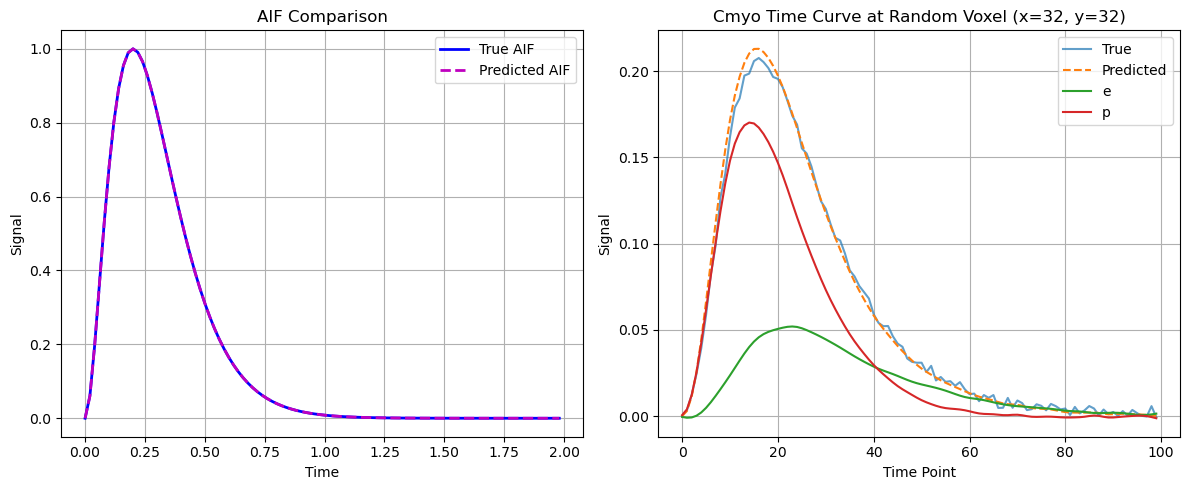

Visualizing Cmyo at voxel (x=24, y=45)


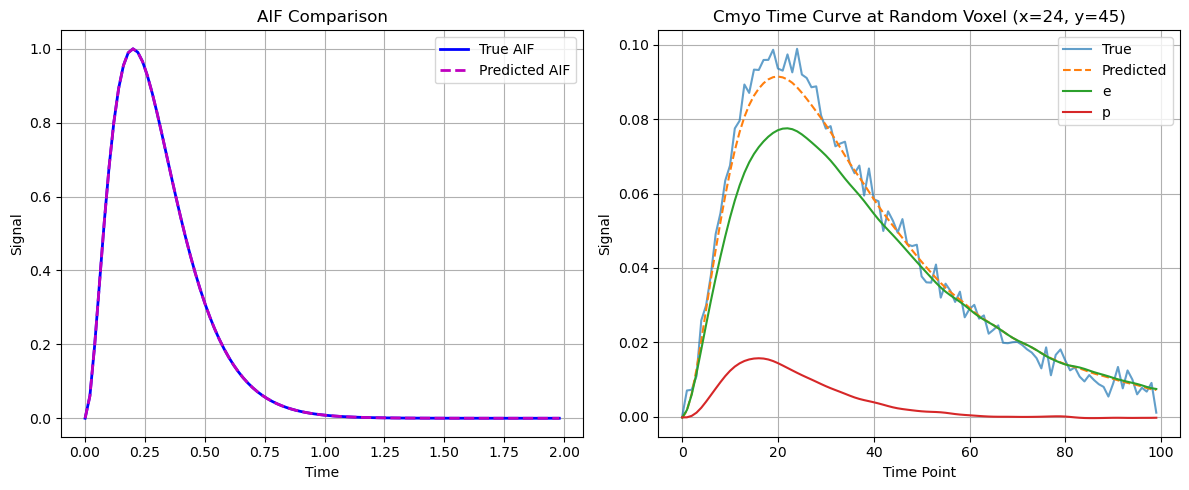

Visualizing Cmyo at voxel (x=20, y=110)


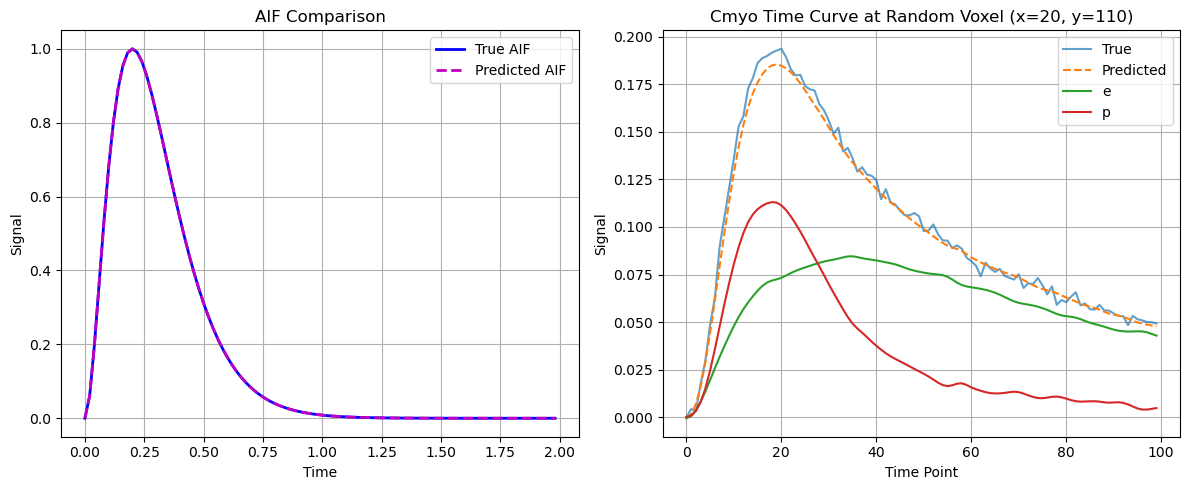

In [ ]:
aif_time, aif, myo_curves, myo_pars = make_dro_no_delay(-1, 0, 17.5) # type: ignore
T, H, W, _ = myo_curves.shape

coordinates = [[32, 32], [24, 45], [20, 110]]

for i in np.arange(0, 3):

    # === AIF tensors ===
    t_tensor_aif = torch.tensor(aif_time.reshape(-1, 1), dtype=torch.float32).to(device)  # [T, 1]
    Y_tensor_aif = torch.tensor(aif.reshape(-1, 1), dtype=torch.float32).to(device)       # [T, 1]

    # Visualise AIF and Cmyo curves at a random voxel
    x_rnd = torch.randint(0, H, (1,)).item()
    y_rnd = torch.randint(0, W, (1,)).item()

    # if i==0:
    #     x_rnd, y_rnd = 20, 110
    # elif i==1:
    #     x_rnd, y_rnd = 20, 90
    x_rnd, y_rnd = coordinates[i][0], coordinates[i][1]

    print(f"Visualizing Cmyo at voxel (x={x_rnd}, y={y_rnd})")

    # Build time-normalized input
    t_norm = np.linspace(0, 2, T).astype(np.float32).reshape(-1, 1)  # [T, 1]
    x_norm = np.full((T, 1), x_rnd / H, dtype=np.float32)
    y_norm = np.full((T, 1), y_rnd / W, dtype=np.float32)

    # Convert to torch tensors
    t_tensor = torch.tensor(t_norm, dtype=torch.float32).to(device)
    xy_tensor = torch.tensor(np.hstack([x_norm, y_norm]), dtype=torch.float32).to(device)

    # === Get voxel-specific myocardial parameters ===
    # myo_pars shape is [H, W, 1, 4] = (40, 120, 1, 4)
    pars_pixel = myo_pars[x_rnd, y_rnd, 0, :]   # [4]

    if torch.is_tensor(pars_pixel):
        pars_pixel = pars_pixel.detach().cpu().numpy()

    # Parameter weights
    scale_e = pars_pixel[2]
    scale_p = pars_pixel[1]

    # Evaluate models
    model_e.eval()
    model_p.eval()

    with torch.no_grad():
        pred_e = model_e(t_tensor, xy_tensor).squeeze().cpu().numpy()
        pred_p = model_p(t_tensor, xy_tensor).squeeze().cpu().numpy()

        pred_pixel = scale_e * pred_e + scale_p * pred_p

    # Get true signal
    true_pixel = myo_curves[:, x_rnd, y_rnd, 0]  # [T]

    # Predict AIF
    model_aif.eval()
    with torch.no_grad():
        pred_aif = model_aif(t_tensor_aif).squeeze().cpu().numpy()

    fig, axs = plt.subplots(1, 2, figsize=(12, 5))

    axs[0].plot(aif_time, aif, 'b-', lw=2, label="True AIF")
    axs[0].plot(aif_time, pred_aif, 'm--', lw=2, label="Predicted AIF")
    axs[0].set_title("AIF Comparison")
    axs[0].set_xlabel("Time")
    axs[0].set_ylabel("Signal")
    axs[0].grid(True)
    axs[0].legend()

    axs[1].plot(true_pixel, label="True", alpha=0.7)
    axs[1].plot(pred_pixel, label="Predicted", linestyle="--")
    axs[1].plot(scale_e*pred_e, label="e", linestyle="-")
    axs[1].plot(scale_p*pred_p, label="p", linestyle="-")
    axs[1].set_title(f"Cmyo Time Curve at Random Voxel (x={x_rnd}, y={y_rnd})")
    axs[1].set_xlabel("Time Point")
    axs[1].set_ylabel("Signal")
    axs[1].legend()
    axs[1].grid(True)

    plt.tight_layout()
    #plt.savefig(f"AIF_and_Myo_curve_x{x_rnd}_y{y_rnd}.png")
    plt.show()

In [ ]:
print("pars_pixel:", pars_pixel)
print("scale_e:", scale_e)
print("scale_p:", scale_p)
print("scale_e + scale_p:", scale_e + scale_p)

Visualizing Cmyo at voxel (x=32, y=32)


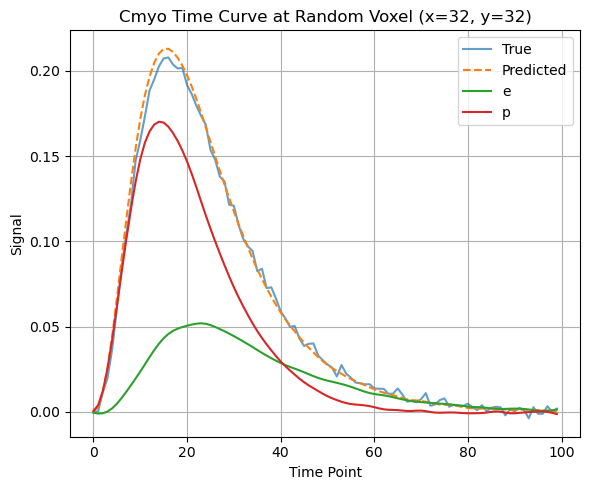

Visualizing Cmyo at voxel (x=24, y=45)


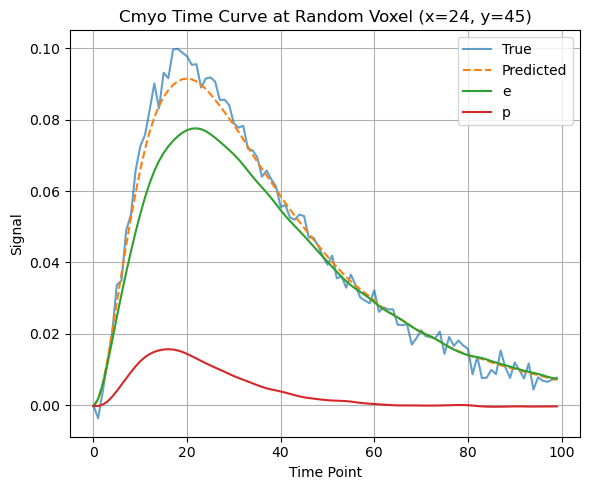

Visualizing Cmyo at voxel (x=20, y=110)


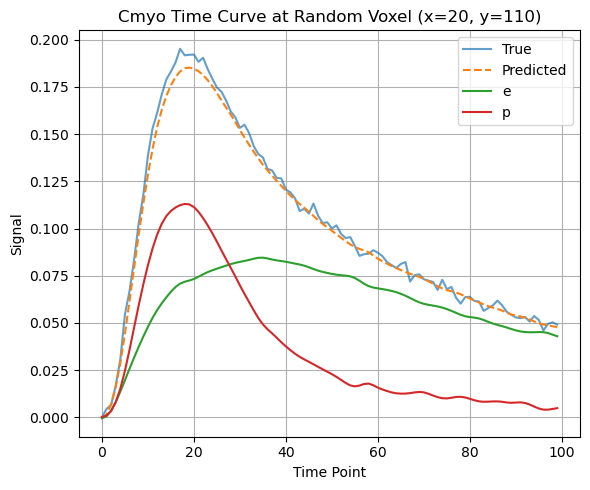

In [ ]:
aif_time, aif, myo_curves, myo_pars = make_dro_no_delay(-1, 0, 17.5) # type: ignore
T, H, W, _ = myo_curves.shape

coordinates = [[32, 32], [24, 45], [20, 110]]

for i in np.arange(0, 3):

    # === AIF tensors ===
    t_tensor_aif = torch.tensor(aif_time.reshape(-1, 1), dtype=torch.float32).to(device)  # [T, 1]
    Y_tensor_aif = torch.tensor(aif.reshape(-1, 1), dtype=torch.float32).to(device)       # [T, 1]

    # Visualise AIF and Cmyo curves at a random voxel
    x_rnd = torch.randint(0, H, (1,)).item()
    y_rnd = torch.randint(0, W, (1,)).item()

    # if i==0:
    #     x_rnd, y_rnd = 20, 110
    # elif i==1:
    #     x_rnd, y_rnd = 20, 90
    x_rnd, y_rnd = coordinates[i][0], coordinates[i][1]

    print(f"Visualizing Cmyo at voxel (x={x_rnd}, y={y_rnd})")

    # Build time-normalized input
    t_norm = np.linspace(0, 2, T).astype(np.float32).reshape(-1, 1)  # [T, 1]
    x_norm = np.full((T, 1), x_rnd / H, dtype=np.float32)
    y_norm = np.full((T, 1), y_rnd / W, dtype=np.float32)

    # Convert to torch tensors
    t_tensor = torch.tensor(t_norm, dtype=torch.float32).to(device)
    xy_tensor = torch.tensor(np.hstack([x_norm, y_norm]), dtype=torch.float32).to(device)

    # === Get voxel-specific myocardial parameters ===
    # myo_pars shape is [H, W, 1, 4] = (40, 120, 1, 4)
    pars_pixel = myo_pars[x_rnd, y_rnd, 0, :]   # [4]

    if torch.is_tensor(pars_pixel):
        pars_pixel = pars_pixel.detach().cpu().numpy()

    # Parameter weights
    scale_e = pars_pixel[2]
    scale_p = pars_pixel[1]

    # Evaluate models
    model_e.eval()
    model_p.eval()

    with torch.no_grad():
        pred_e = model_e(t_tensor, xy_tensor).squeeze().cpu().numpy()
        pred_p = model_p(t_tensor, xy_tensor).squeeze().cpu().numpy()

        pred_pixel = scale_e * pred_e + scale_p * pred_p

    # Get true signal
    true_pixel = myo_curves[:, x_rnd, y_rnd, 0]  # [T]

    # Predict AIF
    model_aif.eval()
    with torch.no_grad():
        pred_aif = model_aif(t_tensor_aif).squeeze().cpu().numpy()

    plt.figure(figsize=(6, 5))

    plt.plot(true_pixel, label="True", alpha=0.7)
    plt.plot(pred_pixel, label="Predicted", linestyle="--")
    plt.plot(scale_e*pred_e, label="e", linestyle="-")
    plt.plot(scale_p*pred_p, label="p", linestyle="-")
    plt.title(f"C\_myo(t) at voxel (x={x_rnd}, y={y_rnd})")
    plt.xlabel("Time Point")
    plt.ylabel("Signal")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    #plt.savefig(f"AIF_and_Myo_curve_x{x_rnd}_y{y_rnd}.png")
    plt.show()